In [2]:

from pathlib import Path
from google.colab import drive

new_mount = Path("/content/gdrive")

new_mount.mkdir(parents=True, exist_ok=True)

drive.mount(str(new_mount))


Mounted at /content/gdrive


Inspect TBX11K splits and annotations

In [ ]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EdgeTB_Project")

TBX_ROOT = (
    ROOT / "data_raw/tbx11k/TBX11K"
)

print("TBX11K DIRECTORY STRUCTURE")


for path in sorted(TBX_ROOT.iterdir()):
    if path.is_dir():
        print("[FOLDER]", path.name)
    else:
        print("[FILE]", path.name)

print("\nPOSSIBLE SPLIT AND ANNOTATION FILES")


extensions = {
    ".txt", ".csv", ".json",
    ".xml", ".xlsx"
}

matches = []

for path in TBX_ROOT.rglob("*"):
    if not path.is_file():
        continue

    # Avoid supplementary image folders.
    if "extra" in path.parts:
        continue

    if path.suffix.lower() in extensions:
        matches.append(path)

for path in matches[:50]:
    print(path.relative_to(TBX_ROOT))

print("\nTotal candidate files:", len(matches))

print("\nIMAGE CATEGORY COUNTS")


for category in ["tb", "health", "sick"]:
    folder = TBX_ROOT / "imgs" / category

    if folder.exists():
        count = sum(
            1 for p in folder.iterdir()
            if p.is_file()
            and p.suffix.lower()
            in {".png", ".jpg", ".jpeg"}
        )

        print(category, ":", count)

print("\nInspection complete.")


TBX11K DIRECTORY STRUCTURE
[FILE] README.md
[FILE] TBX11K_CVPR2020.pdf
[FOLDER] annotations
[FOLDER] code
[FOLDER] imgs
[FOLDER] lists
[FILE] teaser.jpg

POSSIBLE SPLIT AND ANNOTATION FILES
lists/TBX11K_train.txt
lists/TBX11K_trainval.txt
lists/TBX11K_val.txt
lists/all_test.txt
lists/all_train.txt
lists/all_trainval.txt
lists/all_val.txt
annotations/json/TBX11K_train_only_tb.json
annotations/json/all_train.json
annotations/json/TBX11K_val_only_tb.json
annotations/json/TBX11K_trainval.json
annotations/json/TBX11K_train.json
annotations/json/TBX11K_val.json
annotations/json/all_test.json
annotations/json/TBX11K_trainval_only_tb.json
annotations/json/all_trainval.json
annotations/json/all_val.json
annotations/xml/tb0004.xml
annotations/xml/tb0012.xml
annotations/xml/tb0007.xml
annotations/xml/tb0009.xml
annotations/xml/tb0005.xml
annotations/xml/tb0014.xml
annotations/xml/tb0015.xml
annotations/xml/tb0006.xml
annotations/xml/tb0003.xml
annotations/xml/tb0017.xml
annotations/xml/tb0018.xml

In [ ]:

from pathlib import Path
from collections import Counter

ROOT = Path("/content/drive/MyDrive/EdgeTB_Project")
TBX = ROOT / "data_raw/tbx11k/TBX11K"
LISTS = TBX / "lists"

split_files = [
    "TBX11K_train.txt",
    "TBX11K_val.txt",
    "TBX11K_trainval.txt",
    "all_train.txt",
    "all_val.txt",
    "all_test.txt"
]

def read_split(filename):
    path = LISTS / filename

    if not path.exists():
        print("Missing:", filename)
        return []

    return [
        line.strip()
        for line in path.read_text().splitlines()
        if line.strip()
    ]

def identify_category(entry):
    value = entry.lower().replace("\\", "/")
    name = Path(value).name

    if "/tb/" in "/" + value or name.startswith("tb"):
        return "TB"
    elif "/health/" in "/" + value or name.startswith("h"):
        return "Healthy"
    elif "/sick/" in "/" + value or name.startswith("s"):
        return "Other disease"
    else:
        return "Unknown"

print("OFFICIAL TBX11K SPLITS")


for filename in split_files:
    entries = read_split(filename)

    counts = Counter(
        identify_category(entry)
        for entry in entries
    )

    print(f"\n{filename}")
    print("Total entries:", len(entries))
    print("Categories:", dict(counts))
    print("First five entries:", entries[:5])

# Check split overlap using filenames
train = {
    Path(x).name.lower()
    for x in read_split("TBX11K_train.txt")
}
val = {
    Path(x).name.lower()
    for x in read_split("TBX11K_val.txt")
}

print("\nSPLIT OVERLAP CHECK")


print("Train unique images:", len(train))
print("Validation unique images:", len(val))
print("Train/validation overlap:", len(train & val))

if train & val:
    print("Overlapping examples:", sorted(train & val)[:10])

print("\nInspection completed.")


OFFICIAL TBX11K SPLITS

TBX11K_train.txt
Total entries: 6600
Categories: {'TB': 600, 'Healthy': 3000, 'Other disease': 3000}
First five entries: ['tb/tb0005.png', 'tb/tb0007.png', 'tb/tb0012.png', 'tb/tb0017.png', 'tb/tb0018.png']

TBX11K_val.txt
Total entries: 1800
Categories: {'TB': 200, 'Healthy': 800, 'Other disease': 800}
First five entries: ['tb/tb0003.png', 'tb/tb0004.png', 'tb/tb0006.png', 'tb/tb0009.png', 'tb/tb0014.png']

TBX11K_trainval.txt
Total entries: 8400
Categories: {'TB': 800, 'Healthy': 3800, 'Other disease': 3800}
First five entries: ['tb/tb0003.png', 'tb/tb0004.png', 'tb/tb0005.png', 'tb/tb0006.png', 'tb/tb0007.png']

all_train.txt
Total entries: 6888
Categories: {'TB': 600, 'Healthy': 3000, 'Other disease': 3000, 'Unknown': 288}
First five entries: ['tb/tb0005.png', 'tb/tb0007.png', 'tb/tb0012.png', 'tb/tb0017.png', 'tb/tb0018.png']

all_val.txt
Total entries: 2088
Categories: {'TB': 200, 'Healthy': 800, 'Other disease': 800, 'Unknown': 288}
First five entries: ['

Prepare training and validation datasets

In [ ]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/EdgeTB_Project")

TBX_ROOT = ROOT / "data_raw/tbx11k/TBX11K"
IMAGES = TBX_ROOT / "imgs"
LISTS = TBX_ROOT / "lists"

WORK = ROOT / "tbx11k_training_study"
MANIFESTS = WORK / "manifests"

MANIFESTS.mkdir(parents=True, exist_ok=True)

LABEL_MAP = {
    "tb": 1,
    "health": 0,
    "sick": 0
}

def build_manifest(split_name):

    split_file = LISTS / f"TBX11K_{split_name}.txt"

    entries = [
        line.strip()
        for line in split_file.read_text().splitlines()
        if line.strip()
    ]

    rows = []

    for entry in entries:
        relative = Path(entry)
        category = relative.parts[0].lower()

        if category not in LABEL_MAP:
            raise ValueError(
                f"Unexpected category: {entry}"
            )

        image_path = IMAGES / relative

        if not image_path.is_file():
            raise FileNotFoundError(image_path)

        rows.append({
            "image_path": str(image_path),
            "relative_path": entry,
            "category": category,
            "label": LABEL_MAP[category],
            "split": split_name
        })

    df = pd.DataFrame(rows)

    assert not df["relative_path"].duplicated().any()

    output = MANIFESTS / f"tbx11k_{split_name}.csv"
    df.to_csv(output, index=False)

    print(f"\n{split_name.upper()} MANIFEST")

    print("Total images:", len(df))
    print("TB-positive:", int((df["label"] == 1).sum()))
    print("Not TB:", int((df["label"] == 0).sum()))
    print("Missing files:", 0)
    print("Saved to:", output)

    return df

train_df = build_manifest("train")
val_df = build_manifest("val")

# Verify that training and validation are separate.
train_paths = set(train_df["relative_path"])
val_paths = set(val_df["relative_path"])

overlap = train_paths & val_paths

print("\nFINAL DATASET CHECK")


print("Train/validation overlap:", len(overlap))

assert not overlap, "Train/validation overlap detected!"

assert len(train_df) == 6600
assert len(val_df) == 1800

assert int(train_df["label"].sum()) == 600
assert int(val_df["label"].sum()) == 200

# Make sure supplementary Shenzhen images are excluded.
assert not any(
    "extra" in Path(p).parts
    for p in train_df["image_path"]
)

print("\nManifests successfully created.")



TRAIN MANIFEST
Total images: 6600
TB-positive: 600
Not TB: 6000
Missing files: 0
Saved to: /content/drive/MyDrive/EdgeTB_Project/tbx11k_training_study/manifests/tbx11k_train.csv

VAL MANIFEST
Total images: 1800
TB-positive: 200
Not TB: 1600
Missing files: 0
Saved to: /content/drive/MyDrive/EdgeTB_Project/tbx11k_training_study/manifests/tbx11k_val.csv

FINAL DATASET CHECK
Train/validation overlap: 0

Manifests successfully created.


Generate wide-mask images using existing U-Net

U-Net loaded successfully.
Input shape: (None, 256, 256, 1)
Output shape: (None, 256, 256, 1)


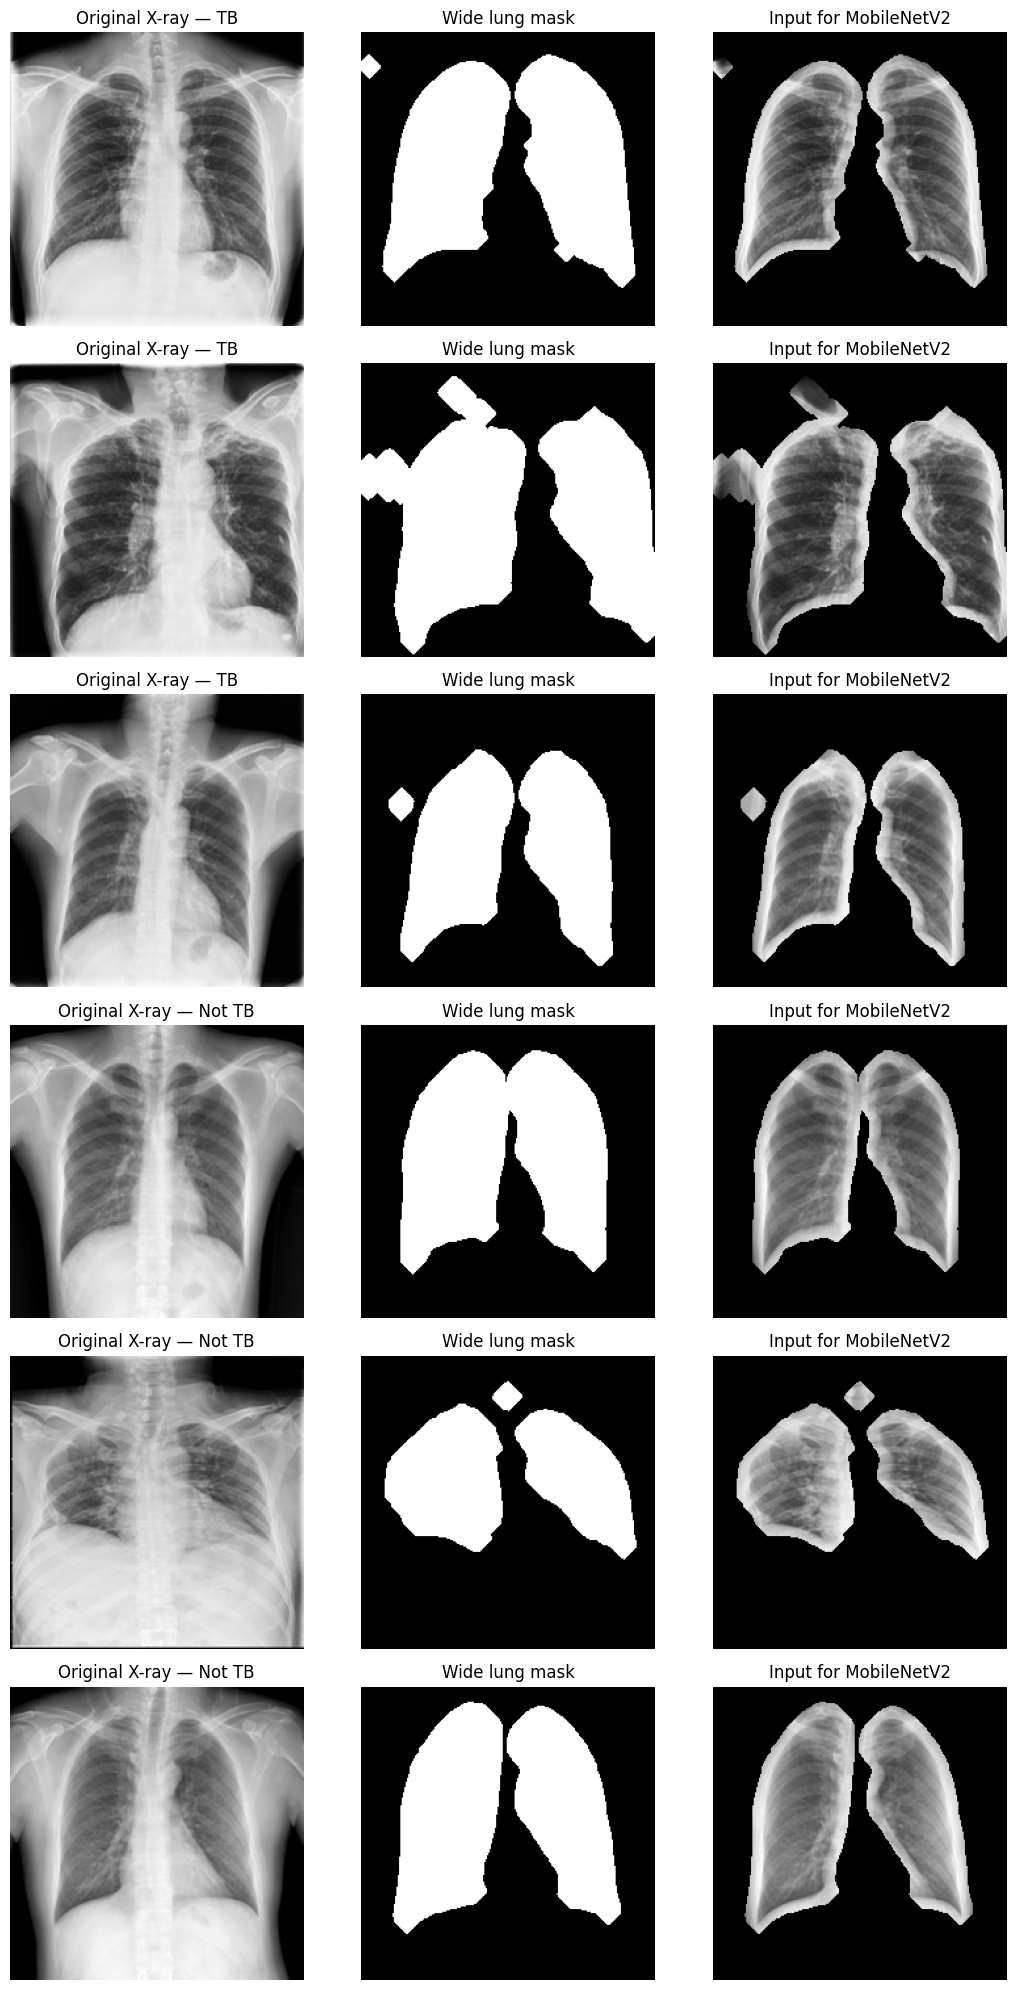


SEGMENTATION TEST COMPLETE
Images processed: 6
Wide-mask shape: (6, 224, 224)


In [ ]:



from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image
from scipy.ndimage import binary_dilation

ROOT = Path("/content/drive/MyDrive/EdgeTB_Project")
WORK = ROOT / "tbx11k_training_study"

UNET_PATH = ROOT / "models/unet_lung.h5"

train_df = pd.read_csv(
    WORK / "manifests/tbx11k_train.csv"
)

# Load existing U-Net.
unet = tf.keras.models.load_model(
    str(UNET_PATH),
    compile=False
)

print("U-Net loaded successfully.")
print("Input shape:", unet.input_shape)
print("Output shape:", unet.output_shape)

# Select 3 TB and 3 non-TB images.
tb_samples = train_df[
    train_df["label"] == 1
].sample(n=3, random_state=42)

non_tb_samples = train_df[
    train_df["label"] == 0
].sample(n=3, random_state=42)

samples = pd.concat(
    [tb_samples, non_tb_samples],
    ignore_index=True
)

def prepare_gray224(path):
    with Image.open(path) as img:
        gray = img.convert("L").resize(
            (224, 224)
        )
        return np.asarray(
            gray, dtype=np.uint8
        )

originals = np.stack([
    prepare_gray224(path)
    for path in samples["image_path"]
])

# Match the previous U-Net preprocessing approach.
unet_inputs = np.stack([
    np.asarray(
        Image.fromarray(img).resize((256, 256)),
        dtype=np.float32
    ) / 255.0
    for img in originals
])[..., None]

predictions = unet.predict(
    unet_inputs,
    batch_size=6,
    verbose=0
)

masks = []
wide_images = []

for original, prediction in zip(
    originals, predictions
):
    binary_mask = (
        prediction[..., 0] > 0.5
    ).astype(np.uint8)

    mask224 = np.asarray(
        Image.fromarray(
            binary_mask * 255
        ).resize(
            (224, 224),
            resample=Image.Resampling.NEAREST
        )
    ) > 127

    wide_mask = binary_dilation(
        mask224,
        iterations=8
    )

    wide_image = (
        original * wide_mask.astype(np.uint8)
    )

    masks.append(wide_mask)
    wide_images.append(wide_image)

# Visualise the segmentation.
fig, axes = plt.subplots(
    6, 3,
    figsize=(11, 20)
)

for i in range(6):
    label = (
        "TB" if samples.iloc[i]["label"] == 1
        else "Not TB"
    )

    axes[i, 0].imshow(
        originals[i],
        cmap="gray"
    )
    axes[i, 0].set_title(
        f"Original X-ray — {label}"
    )

    axes[i, 1].imshow(
        masks[i],
        cmap="gray"
    )
    axes[i, 1].set_title("Wide lung mask")

    axes[i, 2].imshow(
        wide_images[i],
        cmap="gray"
    )
    axes[i, 2].set_title("Input for MobileNetV2")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

print("\nSEGMENTATION TEST COMPLETE")
print("Images processed:", len(wide_images))
print("Wide-mask shape:", np.array(wide_images).shape)


In [ ]:

from pathlib import Path
import json
import numpy as np
import pandas as pd
from PIL import Image
from scipy.ndimage import binary_dilation

root = Path("/content/drive/MyDrive/EdgeTB_Project")
work = root / "tbx11k_training_study"
cache = work / "cache"
cache.mkdir(parents=True, exist_ok=True)

batch_size = 32
grow = 8

def load_gray(path):
    with Image.open(path) as image:
        image = image.convert("L").resize((224, 224))
        return np.asarray(image, dtype=np.uint8)

def generate_wide_masks(images):
    inputs = np.stack([
        np.asarray(
            Image.fromarray(image).resize((256, 256)),
            dtype=np.float32
        ) / 255.0
        for image in images
    ])[..., None]

    predictions = unet.predict(
        inputs,
        batch_size=batch_size,
        verbose=0
    )[..., 0]

    output = []

    for image, prediction in zip(images, predictions):
        mask = (prediction > 0.5).astype(np.uint8)

        mask = np.asarray(
            Image.fromarray(mask * 255).resize(
                (224, 224),
                resample=Image.Resampling.NEAREST
            )
        ) > 127

        mask = binary_dilation(mask, iterations=grow)
        output.append(image * mask.astype(np.uint8))

    return np.stack(output).astype(np.uint8)

def process_split(split):
    manifest = pd.read_csv(
        work / "manifests" / f"tbx11k_{split}.csv"
    )

    total = len(manifest)
    output_path = cache / f"{split}_wide_gray_uint8.npy"
    progress_path = cache / f"{split}_progress.json"

    if progress_path.exists():
        progress = json.loads(progress_path.read_text())
        assert progress["total"] == total
        assert progress["batch_size"] == batch_size
        assert progress["grow"] == grow
        assert output_path.exists()

        start = progress["completed"]

        if start >= total:
            print(f"{split}: already completed")
            return

        array = np.lib.format.open_memmap(
            output_path, mode="r+"
        )

    else:
        if output_path.exists():
            raise RuntimeError(
                f"{output_path} exists without a progress file. "
                "Inspect it before restarting."
            )

        start = 0
        array = np.lib.format.open_memmap(
            output_path,
            mode="w+",
            dtype=np.uint8,
            shape=(total, 224, 224)
        )

        progress_path.write_text(json.dumps({
            "total": total,
            "completed": 0,
            "batch_size": batch_size,
            "grow": grow
        }))

    for offset in range(start, total, batch_size):
        end = min(offset + batch_size, total)

        images = np.stack([
            load_gray(path)
            for path in manifest["image_path"].iloc[offset:end]
        ])

        processed = generate_wide_masks(images)
        array[offset:end] = processed
        array.flush()

        progress_path.write_text(json.dumps({
            "total": total,
            "completed": end,
            "batch_size": batch_size,
            "grow": grow
        }))

        if end % 320 == 0 or end == total:
            print(f"{split}: {end}/{total} images processed")

    del array
    print(f"{split} saved to {output_path}")

process_split("train")
process_split("val")


train: 320/6600 images processed
train: 640/6600 images processed
train: 960/6600 images processed
train: 1280/6600 images processed
train: 1600/6600 images processed
train: 1920/6600 images processed
train: 2240/6600 images processed
train: 2560/6600 images processed
train: 2880/6600 images processed
train: 3200/6600 images processed
train: 3520/6600 images processed
train: 3840/6600 images processed
train: 4160/6600 images processed
train: 4480/6600 images processed
train: 4800/6600 images processed
train: 5120/6600 images processed
train: 5440/6600 images processed
train: 5760/6600 images processed
train: 6080/6600 images processed
train: 6400/6600 images processed
train: 6600/6600 images processed
train saved to /content/drive/MyDrive/EdgeTB_Project/tbx11k_training_study/cache/train_wide_gray_uint8.npy
val: 320/1800 images processed
val: 640/1800 images processed
val: 960/1800 images processed
val: 1280/1800 images processed
val: 1600/1800 images processed
val: 1800/1800 images pro

In [ ]:

import numpy as np

train_path = cache / "train_wide_gray_uint8.npy"
val_path = cache / "val_wide_gray_uint8.npy"

train_images = np.load(train_path, mmap_mode="r")
val_images = np.load(val_path, mmap_mode="r")

assert train_images.shape == (6600, 224, 224)
assert val_images.shape == (1800, 224, 224)

for split, images in [
    ("Train", train_images),
    ("Validation", val_images)
]:
    print(f"{split} shape: {images.shape}")
    print(f"{split} data type: {images.dtype}")

    sample = np.asarray(images[:32])
    print(
        f"{split} sample pixel range:",
        int(sample.min()),
        int(sample.max())
    )

print("Both wide-mask caches have the expected shapes.")


Train shape: (6600, 224, 224)
Train data type: uint8
Train sample pixel range: 0 255
Validation shape: (1800, 224, 224)
Validation data type: uint8
Validation sample pixel range: 0 255
Both wide-mask caches have the expected shapes.


Training MobileNetV2 again

In [ ]:

import random
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

root = Path("/content/drive/MyDrive/EdgeTB_Project")
work = root / "tbx11k_training_study"

cache = work / "cache"
model_dir = work / "models"
results_dir = work / "results"

model_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

seed = 42
batch_size = 32

random.seed(seed)
np.random.seed(seed)
tf.keras.utils.set_random_seed(seed)

train_df = pd.read_csv(
    work / "manifests/tbx11k_train.csv"
)

val_df = pd.read_csv(
    work / "manifests/tbx11k_val.csv"
)

train_images = np.load(
    cache / "train_wide_gray_uint8.npy",
    mmap_mode="r"
)

val_images = np.load(
    cache / "val_wide_gray_uint8.npy",
    mmap_mode="r"
)

y_train = train_df["label"].to_numpy(dtype=np.int32)
y_val = val_df["label"].to_numpy(dtype=np.int32)

assert train_images.shape == (6600, 224, 224)
assert val_images.shape == (1800, 224, 224)
assert len(y_train) == len(train_images)
assert len(y_val) == len(val_images)

assert int(y_train.sum()) == 600
assert int(y_val.sum()) == 200

class ImageSequence(tf.keras.utils.Sequence):
    def __init__(
        self,
        images,
        labels,
        batch_size=32,
        shuffle=False,
        seed=42,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.images = images
        self.labels = np.asarray(labels, dtype=np.float32)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.rng = np.random.default_rng(seed)
        self.indices = np.arange(len(labels))

        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(
            len(self.indices) / self.batch_size
        ))

    def __getitem__(self, index):
        indices = self.indices[
            index * self.batch_size:
            (index + 1) * self.batch_size
        ]

        batch = np.asarray(
            self.images[indices],
            dtype=np.float32
        ) / 255.0

        batch = np.repeat(
            batch[..., None],
            3,
            axis=-1
        )

        labels = self.labels[indices]
        return batch, labels

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.indices)

train_data = ImageSequence(
    train_images,
    y_train,
    batch_size=batch_size,
    shuffle=True,
    seed=seed
)

val_data = ImageSequence(
    val_images,
    y_val,
    batch_size=batch_size
)

backbone = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

backbone.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

x = layers.Rescaling(
    scale=2.0,
    offset=-1.0
)(inputs)

x = layers.RandomRotation(0.03)(x)
x = layers.RandomZoom(0.05)(x)

x = backbone(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    1,
    activation="sigmoid"
)(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.AUC(
            name="roc_auc"
        ),
        tf.keras.metrics.AUC(
            name="pr_auc",
            curve="PR"
        ),
        tf.keras.metrics.Recall(
            name="sensitivity"
        )
    ]
)

negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())

class_weights = {
    0: len(y_train) / (2 * negative_count),
    1: len(y_train) / (2 * positive_count)
}

save_path = (
    model_dir / "mobilenetv2_tbx11k_seed42.keras"
)

callbacks = [
    ModelCheckpoint(
        filepath=str(save_path),
        monitor="val_pr_auc",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_pr_auc",
        mode="max",
        patience=4,
        restore_best_weights=True,
        verbose=1
    )
]

print("Training images:", len(y_train))
print("Validation images:", len(y_val))
print("Class weights:", class_weights)
print("Model input:", model.input_shape)
print("Model output:", model.output_shape)

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=20,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=2
)

history_df = pd.DataFrame(history.history)

history_df.to_csv(
    results_dir / "mobilenetv2_tbx11k_seed42_history.csv",
    index=False
)

print("Best model saved:", save_path)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: 6600
Validation images: 1800
Class weights: {0: 0.55, 1: 5.5}
Model input: (None, 224, 224, 3)
Model output: (None, 1)
Epoch 1/20

Epoch 1: val_pr_auc improved from None to 0.47204, saving model to /content/drive/MyDrive/EdgeTB_Project/tbx11k_training_study/models/mobilenetv2_tbx11k_seed42.keras

Epoch 1: finished saving model to /content/drive/MyDrive/EdgeTB_Project/tbx11k_training_study/models/mobilenetv2_tbx11k_seed42.keras
207/207 - 488s - 2s/step - loss: 0.6261 - pr_auc: 0.2301 - roc_auc: 0.7098 - sensitivity: 0.6433 - val_loss: 0.2815 - val_pr_auc: 0.4720 - val_roc_auc: 0.8434 - val_sensitivity: 0.2050
Epoch 2/20

Epoch 2: val_pr_auc improved from 0.47204 to 0.51240, saving model to /content/drive/MyDrive/EdgeTB_Project/tbx11k_training_study/models/mobilenetv2_tbx11k_seed42.keras

Epoch 2: finished saving model to /content/drive/MyDrive/EdgeTB_Project/tbx11k_training_study/models/mobilenetv2_tbx11k_seed42.keras
207

Evaluate and select a threshold using TBX11K validation

Validation ROC-AUC: 0.9042
Validation average precision: 0.6097

Threshold comparison
              Strategy  Threshold  Sensitivity  Specificity  Precision  TB identified  TB missed  Healthy incorrectly flagged  Other diseases incorrectly flagged
           Default 0.5     0.5000       0.8750       0.7825     0.3346            175         25                          131                                 217
90% sensitivity target     0.4571       0.9000       0.7394     0.3015            180         20                          165                                 252
95% sensitivity target     0.3311       0.9500       0.6075     0.2323            190         10                          291                                 337


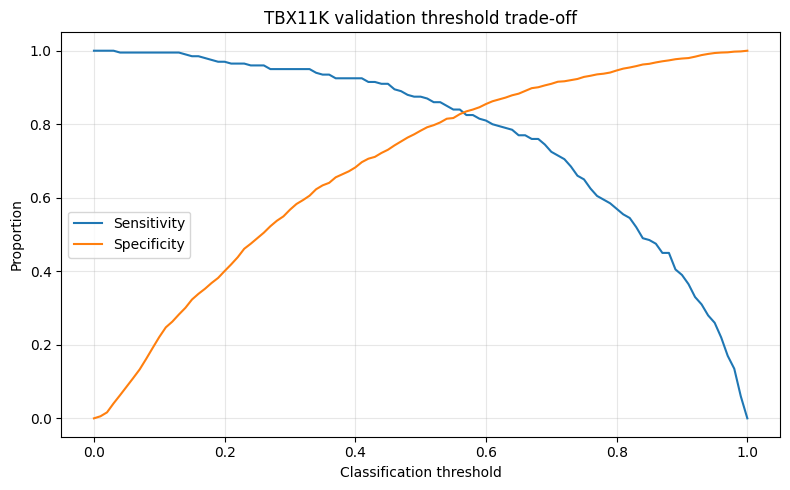


Results saved to: /content/drive/MyDrive/EdgeTB_Project/tbx11k_training_study/results


In [ ]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    confusion_matrix,
    precision_score
)

root = Path("/content/drive/MyDrive/EdgeTB_Project")
work = root / "tbx11k_training_study"

model_path = work / "models/mobilenetv2_tbx11k_seed42.keras"
cache_path = work / "cache/val_wide_gray_uint8.npy"
manifest_path = work / "manifests/tbx11k_val.csv"
results_dir = work / "results"
results_dir.mkdir(parents=True, exist_ok=True)

model = tf.keras.models.load_model(
    str(model_path),
    compile=False
)

images = np.load(cache_path, mmap_mode="r")
manifest = pd.read_csv(manifest_path)

labels = manifest["label"].to_numpy(dtype=int)
categories = manifest["category"].to_numpy()

assert len(images) == len(labels) == 1800
assert int(labels.sum()) == 200

def predict_batches(model, images, batch_size=32):
    predictions = []

    for start in range(0, len(images), batch_size):
        batch = np.asarray(
            images[start:start + batch_size],
            dtype=np.float32
        ) / 255.0

        batch = np.repeat(
            batch[..., None], 3, axis=-1
        )

        scores = model.predict(
            batch, verbose=0
        ).reshape(-1)

        predictions.append(scores)

    return np.concatenate(predictions)

scores = predict_batches(model, images)

roc_auc = roc_auc_score(labels, scores)
pr_auc = average_precision_score(labels, scores)

print(f"Validation ROC-AUC: {roc_auc:.4f}")
print(f"Validation average precision: {pr_auc:.4f}")

# Choose the highest threshold achieving each
# requested sensitivity on validation data.
fpr, tpr, thresholds = roc_curve(labels, scores)

def threshold_for_sensitivity(target):
    eligible = np.where(
        (tpr >= target) & np.isfinite(thresholds)
    )[0]

    if len(eligible) == 0:
        raise ValueError("No eligible threshold found")

    return float(np.max(thresholds[eligible]))

thresholds_to_test = {
    "Default 0.5": 0.5,
    "90% sensitivity target": threshold_for_sensitivity(0.90),
    "95% sensitivity target": threshold_for_sensitivity(0.95)
}

rows = []

for strategy, threshold in thresholds_to_test.items():
    predictions = (scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        labels, predictions, labels=[0, 1]
    ).ravel()

    healthy = categories == "health"
    other_disease = categories == "sick"

    healthy_fp = int(predictions[healthy].sum())
    other_fp = int(predictions[other_disease].sum())

    rows.append({
        "Strategy": strategy,
        "Threshold": threshold,
        "Sensitivity": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "Precision": precision_score(
            labels, predictions, zero_division=0
        ),
        "TB identified": int(tp),
        "TB missed": int(fn),
        "Healthy incorrectly flagged": healthy_fp,
        "Other diseases incorrectly flagged": other_fp
    })

comparison = pd.DataFrame(rows)

print("\nThreshold comparison")
print(
    comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

comparison.to_csv(
    results_dir / "tbx11k_threshold_comparison.csv",
    index=False
)

prediction_table = manifest.copy()
prediction_table["tb_score"] = scores

prediction_table.to_csv(
    results_dir / "tbx11k_validation_predictions.csv",
    index=False
)

# Plot the sensitivity-specificity trade-off.
threshold_grid = np.linspace(0, 1, 101)
sensitivity_values = []
specificity_values = []

for threshold in threshold_grid:
    predicted = scores >= threshold

    sensitivity_values.append(
        predicted[labels == 1].mean()
    )
    specificity_values.append(
        (~predicted[labels == 0]).mean()
    )

plt.figure(figsize=(8, 5))
plt.plot(
    threshold_grid,
    sensitivity_values,
    label="Sensitivity"
)
plt.plot(
    threshold_grid,
    specificity_values,
    label="Specificity"
)

plt.xlabel("Classification threshold")
plt.ylabel("Proportion")
plt.title("TBX11K validation threshold trade-off")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    results_dir / "tbx11k_threshold_tradeoff.png",
    dpi=160
)

plt.show()

print("\nResults saved to:", results_dir)


Test on Shenzhen

In [ ]:

from pathlib import Path
from io import BytesIO
import zipfile

import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from scipy.ndimage import binary_dilation
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

root = Path("/content/drive/MyDrive/EdgeTB_Project")
work = root / "tbx11k_training_study"

zip_path = root / "datasets/shenzhen/archive (7).zip"
unet_path = root / "models/unet_lung.h5"
model_path = work / "models/mobilenetv2_tbx11k_seed42.keras"

results_dir = work / "results"
results_dir.mkdir(parents=True, exist_ok=True)

unet = tf.keras.models.load_model(
    str(unet_path),
    compile=False
)

classifier = tf.keras.models.load_model(
    str(model_path),
    compile=False
)

def load_shenzhen_image(archive, name):
    with archive.open(name) as file:
        with Image.open(BytesIO(file.read())) as image:
            gray = image.convert("L").resize((224, 224))
            return np.asarray(gray, dtype=np.uint8)

def prepare_wide_batch(images):
    unet_input = np.stack([
        np.asarray(
            Image.fromarray(image).resize((256, 256)),
            dtype=np.float32
        ) / 255.0
        for image in images
    ])[..., None]

    masks = unet.predict(
        unet_input,
        batch_size=16,
        verbose=0
    )[..., 0]

    wide_images = []

    for image, prediction in zip(images, masks):
        mask = (prediction > 0.5).astype(np.uint8)

        mask224 = np.asarray(
            Image.fromarray(mask * 255).resize(
                (224, 224),
                resample=Image.Resampling.NEAREST
            )
        ) > 127

        wide_mask = binary_dilation(
            mask224,
            iterations=8
        )

        wide_images.append(
            image * wide_mask.astype(np.uint8)
        )

    batch = np.stack(wide_images).astype(np.float32)
    batch /= 255.0

    return np.repeat(batch[..., None], 3, axis=-1)

with zipfile.ZipFile(zip_path) as archive:
    metadata = pd.read_csv(
        BytesIO(archive.read("shenzhen_metadata.csv"))
    )

    metadata["study_id"] = metadata["study_id"].astype(str)
    assert metadata["study_id"].is_unique
    assert len(metadata) == 662

    metadata["label"] = metadata["study_id"].apply(
        lambda filename: int(
            Path(filename).stem.rsplit("_", 1)[-1]
        )
    )

    assert set(metadata["label"]) == {0, 1}
    assert int(metadata["label"].sum()) == 336
    assert int((metadata["label"] == 0).sum()) == 326

    normal_findings = metadata["findings"].fillna("").str.strip().str.lower()
    assert (normal_findings[metadata["label"] == 0] == "normal").all()
    assert (normal_findings[metadata["label"] == 1] != "normal").all()

    filenames = metadata["study_id"].tolist()

    archive_lookup = {
        Path(name).name: name
        for name in archive.namelist()
        if name.lower().endswith(".png")
    }

    assert all(name in archive_lookup for name in filenames)
    assert len(archive_lookup) == 662

    predictions = []

    for start in range(0, len(filenames), 16):
        batch_names = filenames[start:start + 16]

        originals = np.stack([
            load_shenzhen_image(
                archive,
                archive_lookup[name]
            )
            for name in batch_names
        ])

        masked = prepare_wide_batch(originals)

        scores = classifier.predict(
            masked,
            verbose=0
        ).reshape(-1)

        predictions.extend(scores.tolist())

        print(
            f"Processed {min(start + 16, len(filenames))}"
            f"/{len(filenames)} images"
        )

metadata["tb_score"] = np.asarray(predictions)

y_true = metadata["label"].to_numpy()
y_score = metadata["tb_score"].to_numpy()

print("\nShenzhen external evaluation")
print("Images:", len(metadata))
print("TB:", int(y_true.sum()))
print("Normal:", int((y_true == 0).sum()))
print("ROC-AUC:", round(roc_auc_score(y_true, y_score), 4))
print(
    "Average precision:",
    round(average_precision_score(y_true, y_score), 4)
)

thresholds = {
    "Primary validation-90%": 0.4571,
    "Default 0.5": 0.5,
    "Validation-95%": 0.3311
}

rows = []

for strategy, threshold in thresholds.items():
    y_pred = (y_score >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    rows.append({
        "Strategy": strategy,
        "Threshold": threshold,
        "Sensitivity": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "Precision": tp / (tp + fp) if tp + fp else 0,
        "TP": int(tp),
        "FN": int(fn),
        "TN": int(tn),
        "FP": int(fp)
    })

comparison = pd.DataFrame(rows)

print("\nThreshold comparison")
print(comparison.to_string(index=False))

metadata.to_csv(
    results_dir / "shenzhen_predictions.csv",
    index=False
)

comparison.to_csv(
    results_dir / "shenzhen_external_results.csv",
    index=False
)

print("\nShenzhen results saved.")


Processed 16/662 images
Processed 32/662 images
Processed 48/662 images
Processed 64/662 images
Processed 80/662 images
Processed 96/662 images
Processed 112/662 images
Processed 128/662 images
Processed 144/662 images
Processed 160/662 images
Processed 176/662 images
Processed 192/662 images
Processed 208/662 images
Processed 224/662 images
Processed 240/662 images
Processed 256/662 images
Processed 272/662 images
Processed 288/662 images
Processed 304/662 images
Processed 320/662 images
Processed 336/662 images
Processed 352/662 images
Processed 368/662 images
Processed 384/662 images
Processed 400/662 images
Processed 416/662 images
Processed 432/662 images
Processed 448/662 images
Processed 464/662 images
Processed 480/662 images
Processed 496/662 images
Processed 512/662 images
Processed 528/662 images
Processed 544/662 images
Processed 560/662 images
Processed 576/662 images
Processed 592/662 images
Processed 608/662 images
Processed 624/662 images
Processed 640/662 images
Proces

Inspect Shenzhen prediction scores

Normal image scores
count    326.0000
mean       0.5473
std        0.2729
min        0.0211
25%        0.3021
50%        0.5577
75%        0.8004
max        0.9845
Name: tb_score, dtype: float64

TB image scores
count    336.0000
mean       0.7329
std        0.2127
min        0.1260
25%        0.5958
50%        0.7738
75%        0.9167
max        0.9975
Name: tb_score, dtype: float64


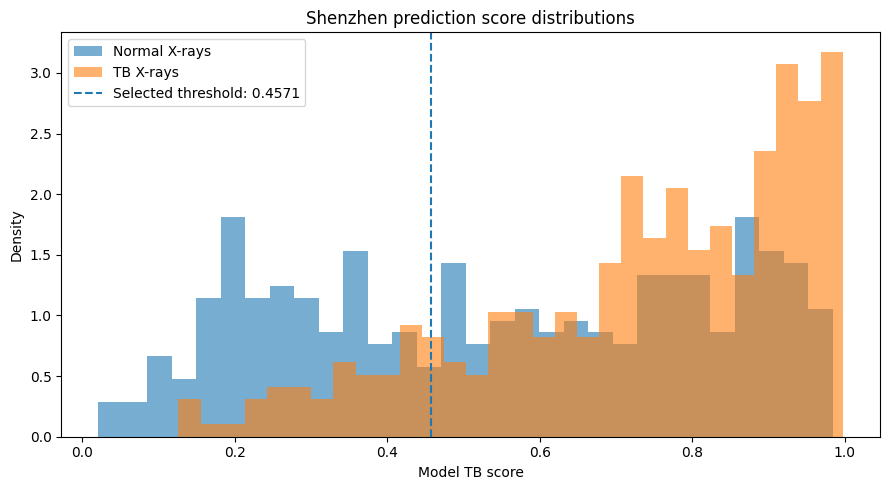


Highest-scoring normal images
         study_id  tb_score
CHNCXR_0065_0.png  0.984451
CHNCXR_0054_0.png  0.982930
CHNCXR_0012_0.png  0.982692
CHNCXR_0265_0.png  0.979763
CHNCXR_0031_0.png  0.972973
CHNCXR_0035_0.png  0.968437
CHNCXR_0086_0.png  0.961378
CHNCXR_0028_0.png  0.961168
CHNCXR_0176_0.png  0.957259
CHNCXR_0081_0.png  0.956509

Lowest-scoring missed TB images
         study_id  tb_score
CHNCXR_0586_1.png  0.126010
CHNCXR_0488_1.png  0.144724
CHNCXR_0614_1.png  0.145861
CHNCXR_0551_1.png  0.156943
CHNCXR_0494_1.png  0.210044
CHNCXR_0584_1.png  0.213330
CHNCXR_0393_1.png  0.221060
CHNCXR_0419_1.png  0.231976
CHNCXR_0381_1.png  0.248251
CHNCXR_0414_1.png  0.258388


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

root = Path("/content/drive/MyDrive/EdgeTB_Project")
results = root / "tbx11k_training_study/results"

df = pd.read_csv(results / "shenzhen_predictions.csv")

normal = df.loc[df["label"] == 0, "tb_score"]
tb = df.loc[df["label"] == 1, "tb_score"]

print("Normal image scores")
print(normal.describe().round(4))

print("\nTB image scores")
print(tb.describe().round(4))

plt.figure(figsize=(9, 5))

plt.hist(
    normal,
    bins=30,
    alpha=0.6,
    density=True,
    label="Normal X-rays"
)

plt.hist(
    tb,
    bins=30,
    alpha=0.6,
    density=True,
    label="TB X-rays"
)

plt.axvline(
    0.4571,
    linestyle="--",
    label="Selected threshold: 0.4571"
)

plt.xlabel("Model TB score")
plt.ylabel("Density")
plt.title("Shenzhen prediction score distributions")
plt.legend()
plt.tight_layout()
plt.show()

normal_flagged = df[
    (df["label"] == 0) &
    (df["tb_score"] >= 0.4571)
].sort_values("tb_score", ascending=False)

tb_missed = df[
    (df["label"] == 1) &
    (df["tb_score"] < 0.4571)
].sort_values("tb_score")

print("\nHighest-scoring normal images")
print(
    normal_flagged[
        ["study_id", "tb_score"]
    ].head(10).to_string(index=False)
)

print("\nLowest-scoring missed TB images")
print(
    tb_missed[
        ["study_id", "tb_score"]
    ].head(10).to_string(index=False)
)


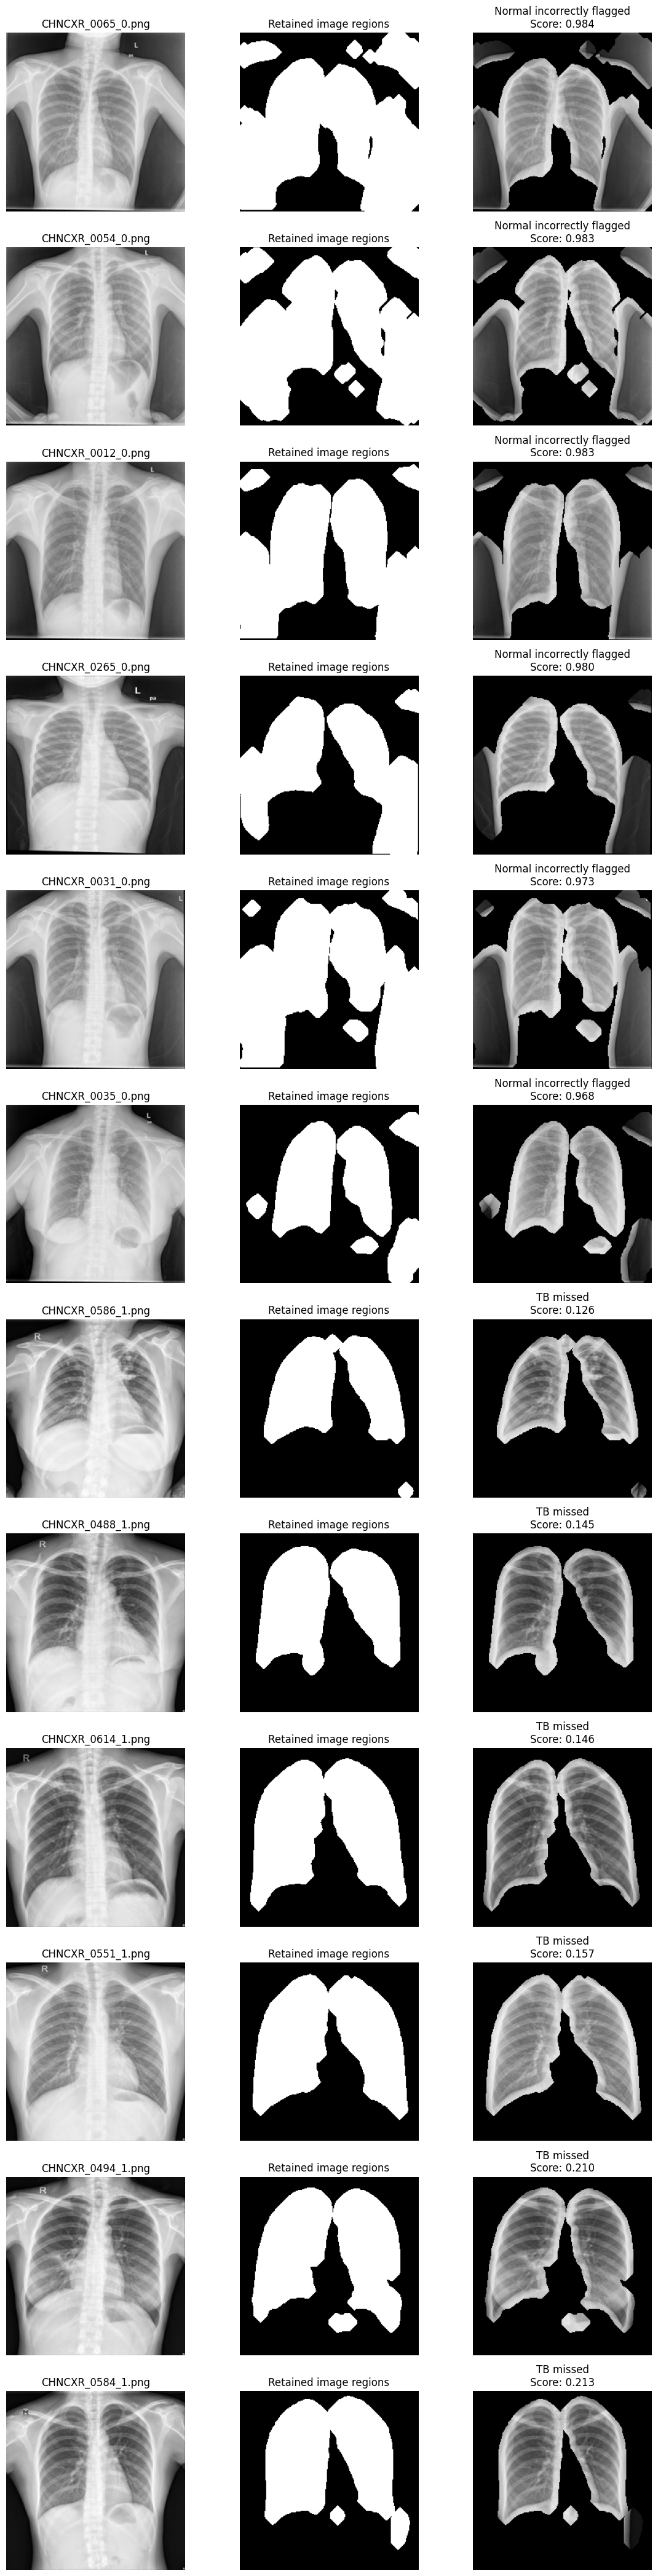

Saved visual comparison: /content/drive/MyDrive/EdgeTB_Project/tbx11k_training_study/results/shenzhen_error_examples.png


In [ ]:

from pathlib import Path
from io import BytesIO
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

root = Path("/content/drive/MyDrive/EdgeTB_Project")
work = root / "tbx11k_training_study"

predictions = pd.read_csv(
    work / "results/shenzhen_predictions.csv"
)

zip_path = root / "datasets/shenzhen/archive (7).zip"

false_positives = (
    predictions[
        (predictions["label"] == 0) &
        (predictions["tb_score"] >= 0.4571)
    ]
    .sort_values("tb_score", ascending=False)
    .head(6)
)

false_negatives = (
    predictions[
        (predictions["label"] == 1) &
        (predictions["tb_score"] < 0.4571)
    ]
    .sort_values("tb_score")
    .head(6)
)

selected = pd.concat(
    [false_positives, false_negatives],
    ignore_index=True
)

fig, axes = plt.subplots(
    len(selected), 3,
    figsize=(12, 3.5 * len(selected))
)

with zipfile.ZipFile(zip_path) as archive:

    file_lookup = {
        Path(name).name: name
        for name in archive.namelist()
        if name.lower().endswith(".png")
    }

    for row, record in enumerate(selected.itertuples()):
        filename = record.study_id

        with archive.open(file_lookup[filename]) as file:
            with Image.open(BytesIO(file.read())) as img:
                original = np.asarray(
                    img.convert("L").resize((224, 224)),
                    dtype=np.uint8
                )

        masked_input = prepare_wide_batch(
            original[None, ...]
        )[0, :, :, 0]

        wide_mask = masked_input > 0

        outcome = (
            "Normal incorrectly flagged"
            if record.label == 0
            else "TB missed"
        )

        axes[row, 0].imshow(original, cmap="gray")
        axes[row, 0].set_title(filename)

        axes[row, 1].imshow(
            wide_mask,
            cmap="gray"
        )
        axes[row, 1].set_title("Retained image regions")

        axes[row, 2].imshow(
            masked_input,
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[row, 2].set_title(
            f"{outcome}\nScore: {record.tb_score:.3f}"
        )

        for ax in axes[row]:
            ax.axis("off")

plt.tight_layout()

output = (
    work / "results/shenzhen_error_examples.png"
)

plt.savefig(output, dpi=150, bbox_inches="tight")
plt.show()

print("Saved visual comparison:", output)


In [ ]:

from pathlib import Path
import json
import numpy as np
import tensorflow as tf

root = Path("/content/drive/MyDrive/EdgeTB_Project")
work = root / "tbx11k_training_study"

model_path = work / "models/mobilenetv2_tbx11k_seed42.keras"
unet_path = root / "models/unet_lung.h5"
config_path = work / "models/prototype_config.json"

assert model_path.is_file(), "Classifier not found"
assert unet_path.is_file(), "U-Net not found"

config = {
    "model_name": "TBX11K wide-mask MobileNetV2",
    "classifier_file": model_path.name,
    "segmentation_file": unet_path.name,
    "threshold": 0.4571,
    "threshold_source": "TBX11K validation, 90% sensitivity target",
    "image_size": [224, 224],
    "unet_image_size": [256, 256],
    "mask_threshold": 0.5,
    "mask_dilation_iterations": 8,
    "classifier_input_scaling": "grayscale / 255, repeated into RGB",
    "training_dataset": "TBX11K",
    "external_dataset": "Shenzhen",
    "external_roc_auc": 0.6982,
    "external_sensitivity": 0.866071,
    "external_specificity": 0.401840,
    "clinical_use": False,
    "status": "Research prototype only"
}

config_path.write_text(
    json.dumps(config, indent=2)
)

classifier = tf.keras.models.load_model(
    str(model_path),
    compile=False
)

images = np.load(
    work / "cache/val_wide_gray_uint8.npy",
    mmap_mode="r"
)

batch = np.asarray(
    images[:4],
    dtype=np.float32
) / 255.0

batch = np.repeat(
    batch[..., None],
    3,
    axis=-1
)

scores = classifier.predict(batch, verbose=0).reshape(-1)

print("Model loaded successfully")
print("Input shape:", classifier.input_shape)
print("Output shape:", classifier.output_shape)
print("Sample scores:", scores.round(4).tolist())
print("Configuration saved:", config_path)


Model loaded successfully
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)
Sample scores: [0.4334000051021576, 0.7954000234603882, 0.8848000168800354, 0.8863000273704529]
Configuration saved: /content/drive/MyDrive/EdgeTB_Project/tbx11k_training_study/models/prototype_config.json


Prepare the full and tight-mask datasets

In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd

root = Path("/content/gdrive/MyDrive/EdgeTB_Project")
work = root / "tbx11k_training_study"

ablation_cache = work / "ablation_study/cache"
wide_cache = work / "cache"

rng = np.random.default_rng(42)
all_checks_passed = True

for split, expected_count in [("train", 6600), ("val", 1800)]:

    full = np.load(
        ablation_cache / f"{split}_full.npy",
        mmap_mode="r"
    )

    tight = np.load(
        ablation_cache / f"{split}_tight.npy",
        mmap_mode="r"
    )

    wide = np.load(
        wide_cache / f"{split}_wide_gray_uint8.npy",
        mmap_mode="r"
    )

    expected_shape = (expected_count, 224, 224)

    for name, images in [
        ("full", full),
        ("tight", tight),
        ("wide", wide)
    ]:
        assert images.shape == expected_shape
        assert images.dtype == np.uint8

    sample_indices = rng.choice(
        expected_count,
        size=min(200, expected_count),
        replace=False
    )

    tight_coverage = []
    wide_coverage = []
    changed_pixels = 0
    mask_violations = 0

    for idx in sample_indices:
        original = np.asarray(full[idx])
        tight_image = np.asarray(tight[idx])
        wide_image = np.asarray(wide[idx])

        tight_coverage.append(np.mean(tight_image > 0))
        wide_coverage.append(np.mean(wide_image > 0))

        mask_violations += np.count_nonzero(
            (tight_image > 0) & (wide_image == 0)
        )

        changed_pixels += np.count_nonzero(
            (wide_image > 0) &
            (wide_image != original)
        )

        changed_pixels += np.count_nonzero(
            (tight_image > 0) &
            (tight_image != original)
        )

    mean_tight = float(np.mean(tight_coverage))
    mean_wide = float(np.mean(wide_coverage))

    passed = (
        mean_wide >= mean_tight
        and mask_violations == 0
        and changed_pixels == 0
    )

    all_checks_passed &= passed

    print(f"\n{split.capitalize()}")
    print("Images:", expected_count)
    print("Average tight retained fraction:", round(mean_tight, 4))
    print("Average wide retained fraction:", round(mean_wide, 4))
    print("Tight pixels missing from wide:", mask_violations)
    print("Changed retained pixel values:", changed_pixels)
    print("Check passed:", passed)

print("\nOverall check passed:", all_checks_passed)

if not all_checks_passed:
    print("Review preprocessing before training.")
else:
    print("Image caches are consistent for the sampled images.")



Train
Images: 6600
Average tight retained fraction: 0.242
Average wide retained fraction: 0.3586
Tight pixels missing from wide: 0
Changed retained pixel values: 0
Check passed: True

Val
Images: 1800
Average tight retained fraction: 0.2451
Average wide retained fraction: 0.3623
Tight pixels missing from wide: 0
Changed retained pixel values: 0
Check passed: True

Overall check passed: True
Image caches are consistent for the sampled images.


In [ ]:

import random
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

model_dir = work / "ablation_study/models"
results_dir = work / "ablation_study/results"

model_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(work / "manifests/tbx11k_train.csv")
val_df = pd.read_csv(work / "manifests/tbx11k_val.csv")

y_train = train_df["label"].to_numpy(dtype=np.int32)
y_val = val_df["label"].to_numpy(dtype=np.int32)

assert len(y_train) == 6600
assert len(y_val) == 1800
assert y_train.sum() == 600
assert y_val.sum() == 200

class ImageSequence(tf.keras.utils.Sequence):
    def __init__(
        self, images, labels,
        batch_size=32, shuffle=False,
        seed=42, **kwargs
    ):
        super().__init__(**kwargs)
        self.images = images
        self.labels = np.asarray(labels, dtype=np.float32)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.rng = np.random.default_rng(seed)
        self.indices = np.arange(len(labels))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.indices) / self.batch_size))

    def __getitem__(self, index):
        ids = self.indices[
            index * self.batch_size:
            (index + 1) * self.batch_size
        ]

        images = np.asarray(
            self.images[ids], dtype=np.float32
        ) / 255.0

        images = np.repeat(images[..., None], 3, axis=-1)
        return images, self.labels[ids]

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.indices)

def build_classifier():
    backbone = MobileNetV2(
        input_shape=(224, 224, 3),
        include_top=False,
        weights="imagenet"
    )

    backbone.trainable = False

    inputs = layers.Input(shape=(224, 224, 3))

    x = layers.Rescaling(
        scale=2.0,
        offset=-1.0
    )(inputs)

    x = layers.RandomRotation(0.03)(x)
    x = layers.RandomZoom(0.05)(x)
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)

    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(0.001),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.AUC(name="roc_auc"),
            tf.keras.metrics.AUC(name="pr_auc", curve="PR"),
            tf.keras.metrics.Recall(name="sensitivity")
        ]
    )

    return model

class_weights = {0: 0.55, 1: 5.5}

def train_variant(variant):
    save_path = model_dir / f"mobilenetv2_{variant}_seed42.keras"
    history_path = results_dir / f"{variant}_history.csv"

    if save_path.exists():
        print(f"\nExisting checkpoint found: {save_path}")
        print("Skipping to avoid overwriting previous results.")
        return

    tf.keras.backend.clear_session()
    random.seed(42)
    np.random.seed(42)
    tf.keras.utils.set_random_seed(42)

    train_images = np.load(
        ablation_cache / f"train_{variant}.npy",
        mmap_mode="r"
    )
    val_images = np.load(
        ablation_cache / f"val_{variant}.npy",
        mmap_mode="r"
    )

    train_data = ImageSequence(
        train_images, y_train,
        batch_size=32, shuffle=True, seed=42
    )

    val_data = ImageSequence(
        val_images, y_val, batch_size=32
    )

    model = build_classifier()

    callbacks = [
        ModelCheckpoint(
            str(save_path),
            monitor="val_pr_auc",
            mode="max",
            save_best_only=True,
            verbose=1
        ),
        EarlyStopping(
            monitor="val_pr_auc",
            mode="max",
            patience=4,
            restore_best_weights=True,
            verbose=1
        )
    ]

    print(f"\nTraining {variant} model")

    history = model.fit(
        train_data,
        validation_data=val_data,
        epochs=20,
        class_weight=class_weights,
        callbacks=callbacks,
        verbose=2
    )

    pd.DataFrame(history.history).to_csv(
        history_path, index=False
    )

    print(f"{variant} model saved:", save_path)

if not all_checks_passed:
    raise RuntimeError("Image cache verification did not pass.")

train_variant("full")
train_variant("tight")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step

Training full model
Epoch 1/20

Epoch 1: val_pr_auc improved from None to 0.66255, saving model to /content/gdrive/MyDrive/EdgeTB_Project/tbx11k_training_study/ablation_study/models/mobilenetv2_full_seed42.keras

Epoch 1: finished saving model to /content/gdrive/MyDrive/EdgeTB_Project/tbx11k_training_study/ablation_study/models/mobilenetv2_full_seed42.keras
207/207 - 32s - 156ms/step - loss: 0.5455 - pr_auc: 0.3595 - roc_auc: 0.7940 - sensitivity: 0.7100 - val_loss: 0.2529 - val_pr_auc: 0.6625 - val_roc_auc: 0.9116 - val_sensitivity: 0.5450
Epoch 2/20

Epoch 2: val_pr_auc improved from 0.66255 to 0.73835, saving model to /content/gdrive/MyDrive/EdgeTB_Project/tbx11k_training_study/ablation_study/models/mobilenetv2_full_seed42.keras

Epoch 2: finished saving model to /content/gdrive/MyDrive/EdgeTB_Project/tbx11k_training_study/ablation_study/models/mobilenetv2_full_seed42.keras
207/207 - 16s - 75ms/step - loss: 0.4074 - pr_auc: 0.5813 - 

In [ ]:

from pathlib import Path
import shutil

source = Path(
    "/content/drive/MyDrive/EdgeTB_Project/"
    "tbx11k_training_study/ablation_study"
)

backup = Path("/content/ablation_local_backup")

if source.exists():
    if backup.exists():
        print("Backup already exists. No files overwritten.")
    else:
        shutil.copytree(source, backup)
        print("Local files backed up to:", backup)

    for path in source.rglob("*"):
        if path.is_file():
            print(
                path.relative_to(source),
                round(path.stat().st_size / 1024**2, 2),
                "MB"
            )
else:
    print("No local ablation files found.")


Local files backed up to: /content/ablation_local_backup


In [ ]:

from pathlib import Path
import json

import numpy as np
import pandas as pd
import tensorflow as tf

from PIL import Image
from scipy.ndimage import binary_dilation

root = Path("/content/drive/MyDrive/EdgeTB_Project")
work = root / "tbx11k_training_study"

manifest_dir = work / "manifests"
source_cache = work / "cache"
ablation_dir = work / "ablation_study"
ablation_cache = ablation_dir / "cache"

ablation_cache.mkdir(parents=True, exist_ok=True)

unet_path = root / "models/unet_lung.h5"

unet = tf.keras.models.load_model(
    str(unet_path),
    compile=False
)

batch_size = 32

def load_gray_image(path):
    with Image.open(path) as image:
        image = image.convert("L")
        image = image.resize(
            (224, 224),
            resample=Image.Resampling.BICUBIC
        )
        return np.asarray(image, dtype=np.uint8)

def predict_tight_masks(images):
    inputs = np.stack([
        np.asarray(
            Image.fromarray(image).resize(
                (256, 256),
                resample=Image.Resampling.BICUBIC
            ),
            dtype=np.float32
        ) / 255.0
        for image in images
    ])[..., None]

    predictions = unet.predict(
        inputs,
        batch_size=batch_size,
        verbose=0
    )[..., 0]

    masks = []

    for prediction in predictions:
        mask256 = (prediction > 0.5).astype(np.uint8)

        mask224 = np.asarray(
            Image.fromarray(mask256 * 255).resize(
                (224, 224),
                resample=Image.Resampling.NEAREST
            )
        ) > 127

        masks.append(mask224)

    return np.stack(masks)

def prepare_split(split):
    manifest = pd.read_csv(
        manifest_dir / f"tbx11k_{split}.csv"
    )

    total = len(manifest)

    full_path = ablation_cache / f"{split}_full.npy"
    tight_path = ablation_cache / f"{split}_tight.npy"
    progress_path = ablation_cache / f"{split}_progress.json"

    if progress_path.exists():
        progress = json.loads(progress_path.read_text())
        assert progress["total"] == total
        assert progress["batch_size"] == batch_size

        completed = progress["completed"]

        full_array = np.lib.format.open_memmap(
            full_path, mode="r+"
        )
        tight_array = np.lib.format.open_memmap(
            tight_path, mode="r+"
        )

    else:
        if full_path.exists() or tight_path.exists():
            raise RuntimeError(
                "Existing cache files found without progress metadata."
            )

        completed = 0

        full_array = np.lib.format.open_memmap(
            full_path,
            mode="w+",
            dtype=np.uint8,
            shape=(total, 224, 224)
        )

        tight_array = np.lib.format.open_memmap(
            tight_path,
            mode="w+",
            dtype=np.uint8,
            shape=(total, 224, 224)
        )

        progress_path.write_text(json.dumps({
            "total": total,
            "batch_size": batch_size,
            "completed": 0
        }))

    for start in range(completed, total, batch_size):
        end = min(start + batch_size, total)

        images = np.stack([
            load_gray_image(path)
            for path in manifest["image_path"].iloc[start:end]
        ])

        masks = predict_tight_masks(images)

        tight_images = (
            images * masks.astype(np.uint8)
        )

        full_array[start:end] = images
        tight_array[start:end] = tight_images

        full_array.flush()
        tight_array.flush()

        progress_path.write_text(json.dumps({
            "total": total,
            "batch_size": batch_size,
            "completed": end
        }))

        if end % 320 == 0 or end == total:
            print(f"{split}: {end}/{total} images")

    del full_array
    del tight_array

    print(f"{split} complete")

# Preprocessing completed and caches saved.
# Run these functions only if the caches need rebuilding.

# prepare_split("train")
# prepare_split("val")


FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = '/content/drive/MyDrive/EdgeTB_Project/models/unet_lung.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [ ]:

from pathlib import Path
import json
import numpy as np

root = Path("/content/gdrive/MyDrive/EdgeTB_Project")
work = root / "tbx11k_training_study"

ablation_cache = work / "ablation_study/cache"
wide_cache = work / "cache"

for split, expected in [("train", 6600), ("val", 1800)]:
    progress_file = ablation_cache / f"{split}_progress.json"

    if not progress_file.exists():
        raise FileNotFoundError(progress_file)

    progress = json.loads(progress_file.read_text())

    assert progress["completed"] == expected, (
        f"{split} preprocessing is incomplete"
    )

    full = np.load(
        ablation_cache / f"{split}_full.npy",
        mmap_mode="r"
    )
    tight = np.load(
        ablation_cache / f"{split}_tight.npy",
        mmap_mode="r"
    )
    wide = np.load(
        wide_cache / f"{split}_wide_gray_uint8.npy",
        mmap_mode="r"
    )

    for name, images in [
        ("Full", full),
        ("Tight", tight),
        ("Wide", wide)
    ]:
        assert images.shape == (expected, 224, 224)
        assert images.dtype == np.uint8

        print(f"{split} {name}: {images.shape}")

    # Compare a reproducible sample of images.
    indices = np.linspace(
        0, expected - 1, 200,
        dtype=int
    )

    tight_coverage = []
    wide_coverage = []
    changed_retained = 0
    missing_tight_pixels = 0

    for idx in indices:
        original = np.asarray(full[idx])
        tight_image = np.asarray(tight[idx])
        wide_image = np.asarray(wide[idx])

        tight_coverage.append(np.mean(tight_image > 0))
        wide_coverage.append(np.mean(wide_image > 0))

        changed_retained += np.count_nonzero(
            (tight_image > 0) &
            (tight_image != original)
        )

        changed_retained += np.count_nonzero(
            (wide_image > 0) &
            (wide_image != original)
        )

        missing_tight_pixels += np.count_nonzero(
            (tight_image > 0) &
            (wide_image == 0)
        )

    print(f"\n{split.capitalize()} coverage")
    print(
        "Tight:",
        round(float(np.mean(tight_coverage)), 4)
    )
    print(
        "Wide:",
        round(float(np.mean(wide_coverage)), 4)
    )
    print("Changed retained pixels:", changed_retained)
    print("Tight pixels absent from wide:", missing_tight_pixels)
    print()

    if changed_retained or missing_tight_pixels:
        print(
            "Warning: Cached variants are not fully consistent "
            "with this sampled comparison."
        )

print("Verification finished.")


train Full: (6600, 224, 224)
train Tight: (6600, 224, 224)
train Wide: (6600, 224, 224)

Train coverage
Tight: 0.2512
Wide: 0.3698
Changed retained pixels: 0
Tight pixels absent from wide: 0

val Full: (1800, 224, 224)
val Tight: (1800, 224, 224)
val Wide: (1800, 224, 224)

Val coverage
Tight: 0.2484
Wide: 0.3682
Changed retained pixels: 0
Tight pixels absent from wide: 0

Verification finished.


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    confusion_matrix
)

root = Path("/content/gdrive/MyDrive/EdgeTB_Project")
work = root / "tbx11k_training_study"

ablation = work / "ablation_study"
results_dir = ablation / "results"
results_dir.mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(
    work / "manifests/tbx11k_val.csv"
)

labels = manifest["label"].to_numpy(dtype=int)
categories = manifest["category"].to_numpy()

assert len(labels) == 1800
assert int(labels.sum()) == 200

paths = {
    "Full X-ray": (
        ablation / "cache/val_full.npy",
        ablation / "models/mobilenetv2_full_seed42.keras"
    ),
    "Tight mask": (
        ablation / "cache/val_tight.npy",
        ablation / "models/mobilenetv2_tight_seed42.keras"
    ),
    "Wide mask": (
        work / "cache/val_wide_gray_uint8.npy",
        work / "models/mobilenetv2_tbx11k_seed42.keras"
    )
}

images = {}
for name, (image_path, model_path) in paths.items():
    assert image_path.is_file(), image_path
    assert model_path.is_file(), model_path

    images[name] = np.load(
        image_path, mmap_mode="r"
    )

    assert images[name].shape == (1800, 224, 224)

# Check consistency of the cached representations.
changed_pixels = 0
missing_tight_pixels = 0

for start in range(0, 1800, 32):
    end = min(start + 32, 1800)

    full = np.asarray(images["Full X-ray"][start:end])
    tight = np.asarray(images["Tight mask"][start:end])
    wide = np.asarray(images["Wide mask"][start:end])

    changed_pixels += int(np.count_nonzero(
        ((tight > 0) & (tight != full)) |
        ((wide > 0) & (wide != full))
    ))

    missing_tight_pixels += int(np.count_nonzero(
        (tight > 0) & (wide == 0)
    ))

print("Changed retained pixels:", changed_pixels)
print("Tight pixels missing from wide:", missing_tight_pixels)

if changed_pixels or missing_tight_pixels:
    print(
        "Warning: Input caches may differ beyond the intended "
        "mask changes. Investigate before treating this as "
        "a strictly controlled ablation."
    )
else:
    print("Validation image representations are consistent.")

def predict_scores(model, image_array):
    scores = []

    for start in range(0, len(image_array), 32):
        batch = np.asarray(
            image_array[start:start + 32],
            dtype=np.float32
        ) / 255.0

        batch = np.repeat(
            batch[..., None], 3, axis=-1
        )

        output = model.predict(
            batch, verbose=0
        ).reshape(-1)

        scores.extend(output.tolist())

    return np.asarray(scores)

def threshold_for_target(y, scores, target=0.90):
    fpr, tpr, thresholds = roc_curve(y, scores)

    eligible = (
        (tpr >= target) &
        np.isfinite(thresholds)
    )

    return float(thresholds[eligible].max())

rows = []
predictions = manifest.copy()

for name, (image_path, model_path) in paths.items():
    print(f"\nEvaluating {name}")

    model = tf.keras.models.load_model(
        str(model_path),
        compile=False
    )

    scores = predict_scores(model, images[name])

    predictions[name + " score"] = scores

    auc = roc_auc_score(labels, scores)
    ap = average_precision_score(labels, scores)

    thresholds = {
        "Default 0.5": 0.5,
        "Validation 90% sensitivity": threshold_for_target(
            labels, scores, 0.90
        )
    }

    for strategy, threshold in thresholds.items():
        predicted = (scores >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            labels, predicted, labels=[0, 1]
        ).ravel()

        rows.append({
            "Model": name,
            "Threshold strategy": strategy,
            "Threshold": threshold,
            "ROC-AUC": auc,
            "Average precision": ap,
            "Sensitivity": tp / (tp + fn),
            "Specificity": tn / (tn + fp),
            "TB identified": int(tp),
            "TB missed": int(fn),
            "Healthy false positives": int(
                predicted[categories == "health"].sum()
            ),
            "Other disease false positives": int(
                predicted[categories == "sick"].sum()
            )
        })

    del model
    tf.keras.backend.clear_session()

comparison = pd.DataFrame(rows)

comparison.to_csv(
    results_dir / "segmentation_ablation_comparison.csv",
    index=False
)

predictions.to_csv(
    results_dir / "segmentation_ablation_predictions.csv",
    index=False
)

print("\nSegmentation comparison")
print(
    comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nResults saved to:", results_dir)


Changed retained pixels: 0
Tight pixels missing from wide: 0
Validation image representations are consistent.

Evaluating Full X-ray

Evaluating Tight mask

Evaluating Wide mask

Segmentation comparison
     Model         Threshold strategy  Threshold  ROC-AUC  Average precision  Sensitivity  Specificity  TB identified  TB missed  Healthy false positives  Other disease false positives
Full X-ray                Default 0.5     0.5000   0.9578             0.8439       0.8400       0.9537            168         32                       15                             59
Full X-ray Validation 90% sensitivity     0.3905   0.9578             0.8439       0.9000       0.9281            180         20                       35                             80
Tight mask                Default 0.5     0.5000   0.9198             0.6919       0.9350       0.6800            187         13                      275                            237
Tight mask Validation 90% sensitivity     0.5900   0.9198

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import roc_auc_score

results_dir = Path(
    "/content/gdrive/MyDrive/EdgeTB_Project/"
    "tbx11k_training_study/ablation_study/results"
)

predictions = pd.read_csv(
    results_dir / "segmentation_ablation_predictions.csv"
)

y = predictions["label"].to_numpy(dtype=int)

models = {
    "Full X-ray": predictions["Full X-ray score"].to_numpy(),
    "Tight mask": predictions["Tight mask score"].to_numpy(),
    "Wide mask": predictions["Wide mask score"].to_numpy()
}

rng = np.random.default_rng(42)

positive_ids = np.where(y == 1)[0]
negative_ids = np.where(y == 0)[0]

bootstrap_results = []

for run in range(1000):
    indices = np.concatenate([
        rng.choice(positive_ids, len(positive_ids), replace=True),
        rng.choice(negative_ids, len(negative_ids), replace=True)
    ])

    aucs = {
        name: roc_auc_score(y[indices], scores[indices])
        for name, scores in models.items()
    }

    bootstrap_results.append({
        "Full vs Tight": aucs["Full X-ray"] - aucs["Tight mask"],
        "Full vs Wide": aucs["Full X-ray"] - aucs["Wide mask"],
        "Tight vs Wide": aucs["Tight mask"] - aucs["Wide mask"]
    })

bootstrap = pd.DataFrame(bootstrap_results)

summary = []

for comparison in bootstrap.columns:
    lower, upper = np.percentile(
        bootstrap[comparison], [2.5, 97.5]
    )

    summary.append({
        "Comparison": comparison,
        "Mean ROC-AUC difference": bootstrap[comparison].mean(),
        "95% CI lower": lower,
        "95% CI upper": upper
    })

summary = pd.DataFrame(summary)

summary.to_csv(
    results_dir / "ablation_bootstrap_confidence_intervals.csv",
    index=False
)

print(summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


   Comparison  Mean ROC-AUC difference  95% CI lower  95% CI upper
Full vs Tight                   0.0376        0.0139        0.0614
 Full vs Wide                   0.0538        0.0341        0.0742
Tight vs Wide                   0.0162       -0.0037        0.0350


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import roc_auc_score, average_precision_score

root = Path("/content/gdrive/MyDrive/EdgeTB_Project")
work = root / "tbx11k_training_study"

cache = work / "ablation_study/cache"
results = work / "ablation_study/results"
results.mkdir(parents=True, exist_ok=True)

model_path = (
    work / "ablation_study/models/"
    "mobilenetv2_full_seed42.keras"
)

manifest = pd.read_csv(
    work / "manifests/tbx11k_val.csv"
)

labels = manifest["label"].to_numpy(dtype=int)

full_images = np.load(
    cache / "val_full.npy", mmap_mode="r"
)

tight_images = np.load(
    cache / "val_tight.npy", mmap_mode="r"
)

model = tf.keras.models.load_model(
    str(model_path), compile=False
)

def get_predictions(images, batch_size=32):
    outputs = []

    for start in range(0, len(images), batch_size):
        batch = np.asarray(
            images[start:start + batch_size],
            dtype=np.float32
        ) / 255.0

        batch = np.repeat(
            batch[..., None], 3, axis=-1
        )

        scores = model.predict(
            batch, verbose=0
        ).reshape(-1)

        outputs.append(scores)

    return np.concatenate(outputs)

original_scores = get_predictions(full_images)
occluded_scores = get_predictions(tight_images)

rows = []

for name, scores in [
    ("Original full X-ray", original_scores),
    ("Background occluded", occluded_scores)
]:
    rows.append({
        "Input": name,
        "ROC-AUC": roc_auc_score(labels, scores),
        "Average precision": average_precision_score(labels, scores),
        "Mean TB score": scores[labels == 1].mean(),
        "Mean non-TB score": scores[labels == 0].mean()
    })

comparison = pd.DataFrame(rows)

comparison.to_csv(
    results / "background_occlusion_comparison.csv",
    index=False
)

prediction_data = manifest.copy()
prediction_data["original_score"] = original_scores
prediction_data["occluded_score"] = occluded_scores
prediction_data["score_change"] = (
    occluded_scores - original_scores
)

prediction_data.to_csv(
    results / "background_occlusion_predictions.csv",
    index=False
)

print(comparison.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

print("\nScore-change statistics:")
print(
    prediction_data["score_change"].describe().round(4)
)

print("\nResults saved.")


              Input  ROC-AUC  Average precision  Mean TB score  Mean non-TB score
Original full X-ray   0.9578             0.8439         0.7702             0.1019
Background occluded   0.4823             0.1138         0.4107             0.4262

Score-change statistics:
count    1800.0000
mean        0.2483
std         0.3662
min        -0.9724
25%         0.0537
50%         0.2841
75%         0.5181
max         0.9630
Name: score_change, dtype: float64

Results saved.


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import roc_auc_score, average_precision_score

root = Path("/content/gdrive/MyDrive/EdgeTB_Project")
work = root / "tbx11k_training_study"
ablation = work / "ablation_study"

labels = pd.read_csv(
    work / "manifests/tbx11k_val.csv"
)["label"].to_numpy(dtype=int)

image_paths = {
    "Full": ablation / "cache/val_full.npy",
    "Tight": ablation / "cache/val_tight.npy",
    "Wide": work / "cache/val_wide_gray_uint8.npy"
}

model_paths = {
    "Full": ablation / "models/mobilenetv2_full_seed42.keras",
    "Tight": ablation / "models/mobilenetv2_tight_seed42.keras",
    "Wide": work / "models/mobilenetv2_tbx11k_seed42.keras"
}

images = {
    name: np.load(path, mmap_mode="r")
    for name, path in image_paths.items()
}

def evaluate_input(model, array):
    scores = []

    for start in range(0, len(array), 32):
        batch = np.asarray(
            array[start:start + 32],
            dtype=np.float32
        ) / 255.0

        batch = np.repeat(batch[..., None], 3, axis=-1)

        scores.append(
            model.predict(batch, verbose=0).reshape(-1)
        )

    return np.concatenate(scores)

records = []

for model_name, model_path in model_paths.items():
    print(f"Evaluating {model_name} classifier")

    model = tf.keras.models.load_model(
        str(model_path), compile=False
    )

    for input_name, image_array in images.items():
        scores = evaluate_input(model, image_array)

        records.append({
            "Trained model": model_name,
            "Input": input_name,
            "ROC-AUC": roc_auc_score(labels, scores),
            "Average precision": average_precision_score(
                labels, scores
            )
        })

    del model
    tf.keras.backend.clear_session()

comparison = pd.DataFrame(records)

roc_table = comparison.pivot(
    index="Trained model",
    columns="Input",
    values="ROC-AUC"
).reindex(index=["Full", "Tight", "Wide"],
          columns=["Full", "Tight", "Wide"])

ap_table = comparison.pivot(
    index="Trained model",
    columns="Input",
    values="Average precision"
).reindex(index=["Full", "Tight", "Wide"],
          columns=["Full", "Tight", "Wide"])

print("\nROC-AUC comparison")
print(roc_table.round(4).to_string())

print("\nAverage precision comparison")
print(ap_table.round(4).to_string())

output = ablation / "results/cross_representation_robustness.csv"
comparison.to_csv(output, index=False)

print("\nSaved:", output)


Evaluating Full classifier
Evaluating Tight classifier
Evaluating Wide classifier

ROC-AUC comparison
Input            Full   Tight    Wide
Trained model                        
Full           0.9578  0.4823  0.6232
Tight          0.6642  0.9198  0.8713
Wide           0.7894  0.8300  0.9042

Average precision comparison
Input            Full   Tight    Wide
Trained model                        
Full           0.8439  0.1138  0.1803
Tight          0.1962  0.6919  0.5245
Wide           0.3357  0.4557  0.6097

Saved: /content/gdrive/MyDrive/EdgeTB_Project/tbx11k_training_study/ablation_study/results/cross_representation_robustness.csv


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf

from scipy.ndimage import gaussian_filter

root = Path("/content/gdrive/MyDrive/EdgeTB_Project")
work = root / "tbx11k_training_study"
ablation = work / "ablation_study"

results_dir = ablation / "results"
results_dir.mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(
    work / "manifests/tbx11k_val.csv"
)

full_images = np.load(
    ablation / "cache/val_full.npy",
    mmap_mode="r"
)

tight_images = np.load(
    ablation / "cache/val_tight.npy",
    mmap_mode="r"
)

model = tf.keras.models.load_model(
    str(
        ablation /
        "models/mobilenetv2_full_seed42.keras"
    ),
    compile=False
)

rng = np.random.default_rng(42)

selected = []

for category in ["tb", "health", "sick"]:
    ids = np.where(
        manifest["category"].to_numpy() == category
    )[0]

    selected.extend(
        rng.choice(ids, size=20, replace=False)
    )

def predict_batch(images, batch_size=32):
    images = np.asarray(images, dtype=np.float32) / 255.0
    images = np.repeat(images[..., None], 3, axis=-1)

    return model.predict(
        images,
        batch_size=batch_size,
        verbose=0
    ).reshape(-1)

grid_size = 7
patch_size = 224 // grid_size

records = []
importance_maps = []

for position, idx in enumerate(selected):
    image = np.asarray(full_images[idx], dtype=np.uint8)
    tight = np.asarray(tight_images[idx], dtype=np.uint8)

    original_score = float(
        predict_batch(image[None, ...])[0]
    )

    blurred = gaussian_filter(
        image.astype(np.float32),
        sigma=6
    ).astype(np.uint8)

    altered_images = []
    patch_locations = []

    for row in range(grid_size):
        for col in range(grid_size):
            y1 = row * patch_size
            y2 = y1 + patch_size

            x1 = col * patch_size
            x2 = x1 + patch_size

            altered = image.copy()

            altered[y1:y2, x1:x2] = blurred[
                y1:y2, x1:x2
            ]

            altered_images.append(altered)
            patch_locations.append((row, col, y1, y2, x1, x2))

    altered_scores = predict_batch(
        np.stack(altered_images)
    )

    importance = np.zeros(
        (grid_size, grid_size),
        dtype=np.float32
    )

    for score, location in zip(
        altered_scores, patch_locations
    ):
        row, col, y1, y2, x1, x2 = location

        change = abs(original_score - float(score))

        importance[row, col] = change

        # Approximate retained lung pixels.
        lung_region = (
            (tight[y1:y2, x1:x2] > 0) &
            (image[y1:y2, x1:x2] > 0)
        )

        lung_fraction = float(lung_region.mean())

        records.append({
            "image_index": int(idx),
            "category": manifest.iloc[idx]["category"],
            "label": int(manifest.iloc[idx]["label"]),
            "row": row,
            "column": col,
            "original_score": original_score,
            "altered_score": float(score),
            "absolute_change": change,
            "lung_fraction": lung_fraction
        })

    importance_maps.append(importance)

    if (position + 1) % 10 == 0:
        print(
            f"Processed {position + 1}/{len(selected)} images"
        )

results = pd.DataFrame(records)

results["region"] = np.where(
    results["lung_fraction"] >= 0.5,
    "Predominantly lung",
    "Predominantly outside lung"
)

summary = results.groupby(
    ["category", "region"]
)["absolute_change"].agg(
    ["mean", "median", "count"]
).reset_index()

results.to_csv(
    results_dir / "patch_perturbation_results.csv",
    index=False
)

summary.to_csv(
    results_dir / "patch_perturbation_summary.csv",
    index=False
)

np.save(
    results_dir / "patch_importance_maps.npy",
    np.stack(importance_maps)
)

np.save(
    results_dir / "patch_selected_indices.npy",
    np.asarray(selected)
)

print("\nPatch sensitivity summary")
print(summary.to_string(index=False))

print("\nAll results saved.")


Processed 10/60 images
Processed 20/60 images
Processed 30/60 images
Processed 40/60 images
Processed 50/60 images
Processed 60/60 images

Patch sensitivity summary
category                     region     mean   median  count
  health         Predominantly lung 0.058060 0.038210    245
  health Predominantly outside lung 0.037449 0.018160    735
    sick         Predominantly lung 0.030057 0.013046    212
    sick Predominantly outside lung 0.021017 0.006094    768
      tb         Predominantly lung 0.094682 0.040283    227
      tb Predominantly outside lung 0.054445 0.014972    753

All results saved.


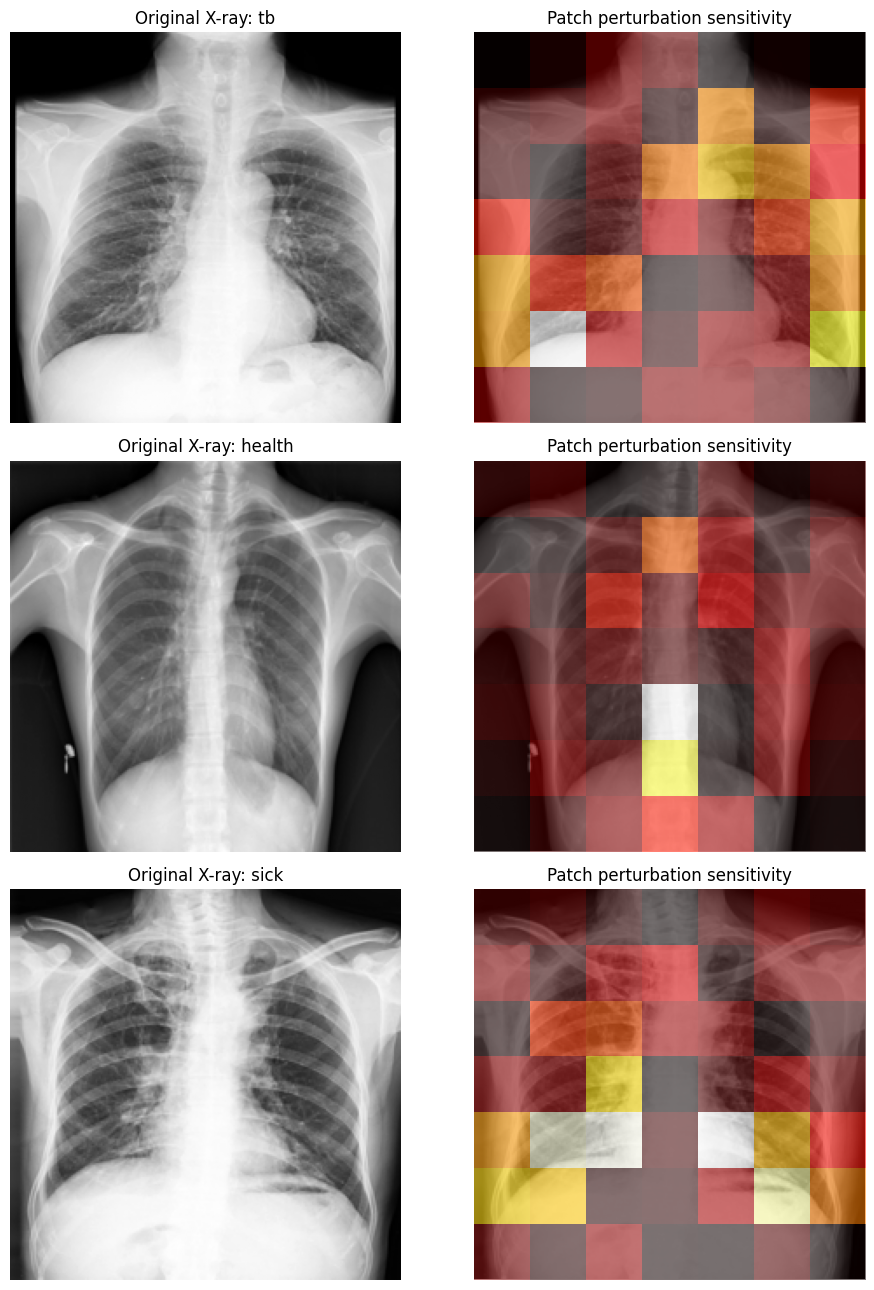

Figure saved: /content/gdrive/MyDrive/EdgeTB_Project/tbx11k_training_study/ablation_study/results/patch_perturbation_examples.png


In [ ]:

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(
    3, 2,
    figsize=(10, 13)
)

examples = [0, 20, 40]

for row, position in enumerate(examples):
    idx = selected[position]

    image = np.asarray(full_images[idx])

    importance = importance_maps[position]
    category = manifest.iloc[idx]["category"]

    axes[row, 0].imshow(
        image,
        cmap="gray"
    )

    axes[row, 0].set_title(
        f"Original X-ray: {category}"
    )

    axes[row, 1].imshow(
        image,
        cmap="gray"
    )

    axes[row, 1].imshow(
        importance,
        cmap="hot",
        alpha=0.55,
        extent=(0, 224, 224, 0),
        interpolation="nearest"
    )

    axes[row, 1].set_title(
        "Patch perturbation sensitivity"
    )

    axes[row, 0].axis("off")
    axes[row, 1].axis("off")

plt.tight_layout()

figure_path = (
    results_dir /
    "patch_perturbation_examples.png"
)

plt.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:", figure_path)


In [ ]:

from pathlib import Path
import json
import numpy as np
import pandas as pd
import tensorflow as tf

root = Path("/content/gdrive/MyDrive/EdgeTB_Project")
work = root / "tbx11k_training_study"
ablation = work / "ablation_study"

output_dir = ablation / "edge_deployment"
output_dir.mkdir(parents=True, exist_ok=True)

model_paths = {
    "full": ablation / "models/mobilenetv2_full_seed42.keras",
    "tight": ablation / "models/mobilenetv2_tight_seed42.keras",
    "wide": work / "models/mobilenetv2_tbx11k_seed42.keras"
}

cache_paths = {
    "full": ablation / "cache/val_full.npy",
    "tight": ablation / "cache/val_tight.npy",
    "wide": work / "cache/val_wide_gray_uint8.npy"
}

records = []

for variant in ["full", "tight", "wide"]:
    print(f"\nConverting {variant} classifier")

    keras_path = model_paths[variant]
    tflite_path = output_dir / f"mobilenetv2_{variant}_fp32.tflite"

    model = tf.keras.models.load_model(
        str(keras_path),
        compile=False
    )

    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    tflite_model = converter.convert()

    tflite_path.write_bytes(tflite_model)

    interpreter = tf.lite.Interpreter(
        model_path=str(tflite_path),
        num_threads=2
    )
    interpreter.allocate_tensors()

    input_info = interpreter.get_input_details()[0]
    output_info = interpreter.get_output_details()[0]

    assert input_info["dtype"] == np.float32

    images = np.load(
        cache_paths[variant],
        mmap_mode="r"
    )

    sample_ids = [0, 100, 500, 1000, 1700]
    differences = []

    for idx in sample_ids:
        image = np.asarray(
            images[idx],
            dtype=np.float32
        ) / 255.0

        batch = np.repeat(
            image[..., None],
            3,
            axis=-1
        )[None, ...]

        keras_score = float(
            model(batch, training=False).numpy().reshape(-1)[0]
        )

        interpreter.set_tensor(
            input_info["index"],
            batch.astype(input_info["dtype"])
        )

        interpreter.invoke()

        tflite_score = float(
            interpreter.get_tensor(
                output_info["index"]
            ).reshape(-1)[0]
        )

        differences.append(
            abs(keras_score - tflite_score)
        )

    max_difference = float(max(differences))

    records.append({
        "Model": variant,
        "Size MB": tflite_path.stat().st_size / (1024 ** 2),
        "Max prediction difference": max_difference,
        "Input shape": str(input_info["shape"].tolist()),
        "Input dtype": str(input_info["dtype"])
    })

    print("Saved:", tflite_path)
    print("Maximum prediction difference:", max_difference)

    del model
    del interpreter
    tf.keras.backend.clear_session()

summary = pd.DataFrame(records)

summary.to_csv(
    output_dir / "conversion_results.csv",
    index=False
)

print("\nConversion summary")
print(summary.to_string(index=False))



Converting full classifier
Saved artifact at '/tmp/tmpv8wn5ow2'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  133467855788688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133467855783696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133467855789072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133467855781968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133467855791376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133467857484304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133467857471632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133467857472976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133467857471440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133467857481616: TensorSpec(shape=(), dtype=tf.resource

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Saved: /content/gdrive/MyDrive/EdgeTB_Project/tbx11k_training_study/ablation_study/edge_deployment/mobilenetv2_full_fp32.tflite
Maximum prediction difference: 1.3113021850585938e-06

Converting tight classifier
Saved artifact at '/tmp/tmpagnamtha'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  133467777857296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133467777859216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133467777856912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133467777855376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133467777858640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133467777854992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133467777855952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133467777856

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Saved: /content/gdrive/MyDrive/EdgeTB_Project/tbx11k_training_study/ablation_study/edge_deployment/mobilenetv2_tight_fp32.tflite
Maximum prediction difference: 1.9073486328125e-06

Converting wide classifier
Saved artifact at '/tmp/tmpq44met5y'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  133467857470864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133467857481808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133467857484304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133467857471248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133467857471632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133468938307536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133467857470672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133467857480080

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Saved: /content/gdrive/MyDrive/EdgeTB_Project/tbx11k_training_study/ablation_study/edge_deployment/mobilenetv2_wide_fp32.tflite
Maximum prediction difference: 8.940696716308594e-07

Conversion summary
Model  Size MB  Max prediction difference      Input shape             Input dtype
 full 8.478134               1.311302e-06 [1, 224, 224, 3] <class 'numpy.float32'>
tight 8.478134               1.907349e-06 [1, 224, 224, 3] <class 'numpy.float32'>
 wide 8.478134               8.940697e-07 [1, 224, 224, 3] <class 'numpy.float32'>


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

root = Path("/content/gdrive/MyDrive/EdgeTB_Project")
work = root / "tbx11k_training_study"
ablation = work / "ablation_study"

edge_dir = ablation / "edge_deployment"
results_dir = ablation / "results"

original = pd.read_csv(
    results_dir / "segmentation_ablation_predictions.csv"
)

comparison = pd.read_csv(
    results_dir / "segmentation_ablation_comparison.csv"
)

labels = original["label"].to_numpy(dtype=int)

variants = {
    "full": {
        "name": "Full X-ray",
        "cache": ablation / "cache/val_full.npy"
    },
    "tight": {
        "name": "Tight mask",
        "cache": ablation / "cache/val_tight.npy"
    },
    "wide": {
        "name": "Wide mask",
        "cache": work / "cache/val_wide_gray_uint8.npy"
    }
}

records = []

for variant, config in variants.items():
    name = config["name"]

    print(f"\nValidating {name}")

    images = np.load(
        config["cache"],
        mmap_mode="r"
    )

    interpreter = tf.lite.Interpreter(
        model_path=str(
            edge_dir / f"mobilenetv2_{variant}_fp32.tflite"
        ),
        num_threads=2
    )

    interpreter.allocate_tensors()

    input_info = interpreter.get_input_details()[0]
    output_info = interpreter.get_output_details()[0]

    assert input_info["shape"].tolist() == [1, 224, 224, 3]
    assert input_info["dtype"] == np.float32
    assert len(images) == len(labels) == 1800

    scores = np.empty(len(images), dtype=np.float32)

    for idx in range(len(images)):
        image = np.asarray(
            images[idx], dtype=np.float32
        ) / 255.0

        batch = np.repeat(
            image[..., None], 3, axis=-1
        )[None, ...]

        interpreter.set_tensor(
            input_info["index"],
            batch
        )

        interpreter.invoke()

        scores[idx] = interpreter.get_tensor(
            output_info["index"]
        ).reshape(-1)[0]

        if (idx + 1) % 300 == 0:
            print(f"{idx + 1}/1800")

    keras_scores = original[
        f"{name} score"
    ].to_numpy(dtype=float)

    threshold_row = comparison[
        (comparison["Model"] == name) &
        (
            comparison["Threshold strategy"] ==
            "Validation 90% sensitivity"
        )
    ]

    assert len(threshold_row) == 1
    threshold = float(threshold_row.iloc[0]["Threshold"])

    # Reuse the original validation-selected threshold.
    predicted = (scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        labels, predicted, labels=[0, 1]
    ).ravel()

    roc_auc = roc_auc_score(labels, scores)
    ap = average_precision_score(labels, scores)

    original_auc = roc_auc_score(labels, keras_scores)
    original_ap = average_precision_score(
        labels, keras_scores
    )

    records.append({
        "Model": name,
        "Max absolute score difference": float(
            np.max(np.abs(scores - keras_scores))
        ),
        "Mean absolute score difference": float(
            np.mean(np.abs(scores - keras_scores))
        ),
        "Keras ROC-AUC": original_auc,
        "TFLite ROC-AUC": roc_auc,
        "ROC-AUC difference": roc_auc - original_auc,
        "Keras AP": original_ap,
        "TFLite AP": ap,
        "AP difference": ap - original_ap,
        "Sensitivity": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "False positives": int(fp),
        "False negatives": int(fn)
    })

    del interpreter

summary = pd.DataFrame(records)

summary.to_csv(
    edge_dir / "tflite_full_validation.csv",
    index=False
)

print("\nTensorFlow Lite validation results")
print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\nSaved:", edge_dir / "tflite_full_validation.csv")



Validating Full X-ray


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


300/1800
600/1800
900/1800
1200/1800
1500/1800
1800/1800

Validating Tight mask


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


300/1800
600/1800
900/1800
1200/1800
1500/1800
1800/1800

Validating Wide mask


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


300/1800
600/1800
900/1800
1200/1800
1500/1800
1800/1800

TensorFlow Lite validation results
     Model  Max absolute score difference  Mean absolute score difference  Keras ROC-AUC  TFLite ROC-AUC  ROC-AUC difference  Keras AP  TFLite AP  AP difference  Sensitivity  Specificity  False positives  False negatives
Full X-ray                       0.000011                        0.000001       0.957794        0.957794            0.000000  0.843881   0.843881       0.000000     0.895000     0.928125              115               21
Tight mask                       0.000008                        0.000001       0.919837        0.919837            0.000000  0.691927   0.691927       0.000000     0.900000     0.770000              368               20
 Wide mask                       0.000007                        0.000001       0.904231        0.904231            0.000000  0.609692   0.609692       0.000000     0.900000     0.739375              417               20

Saved: /content/gdrive

In [3]:

from pathlib import Path
import time
import numpy as np
import pandas as pd
import tensorflow as tf

root = Path("/content/gdrive/MyDrive/EdgeTB_Project")
work = root / "tbx11k_training_study"
ablation = work / "ablation_study"
edge_dir = ablation / "edge_deployment"

variants = {
    "full": ablation / "cache/val_full.npy",
    "tight": ablation / "cache/val_tight.npy",
    "wide": work / "cache/val_wide_gray_uint8.npy"
}

warmup_runs = 15
timed_runs = 150
rng = np.random.default_rng(42)

records = []

for name, cache_path in variants.items():
    model_path = edge_dir / f"mobilenetv2_{name}_fp32.tflite"

    images = np.load(cache_path, mmap_mode="r")

    selected = rng.choice(
        len(images), size=timed_runs, replace=False
    )

    interpreter = tf.lite.Interpreter(
        model_path=str(model_path),
        num_threads=2
    )
    interpreter.allocate_tensors()

    input_info = interpreter.get_input_details()[0]
    output_info = interpreter.get_output_details()[0]

    prepared = []

    for idx in selected:
        gray = np.asarray(
            images[idx], dtype=np.float32
        ) / 255.0

        prepared.append(
            np.repeat(gray[..., None], 3, axis=-1)[None, ...]
        )

    for batch in prepared[:warmup_runs]:
        interpreter.set_tensor(input_info["index"], batch)
        interpreter.invoke()
        interpreter.get_tensor(output_info["index"])

    inference_times = []

    for batch in prepared:
        interpreter.set_tensor(input_info["index"], batch)

        start = time.perf_counter()
        interpreter.invoke()
        duration = time.perf_counter() - start

        inference_times.append(duration * 1000)

    inference_times = np.asarray(inference_times)

    records.append({
        "Model": name,
        "Model size MB": model_path.stat().st_size / 1024**2,
        "Mean inference ms": inference_times.mean(),
        "Median inference ms": np.median(inference_times),
        "P95 inference ms": np.percentile(inference_times, 95),
        "Images per second": 1000 / inference_times.mean(),
        "CPU threads": 2,
        "Timed images": timed_runs
    })

    del interpreter

benchmark = pd.DataFrame(records)

benchmark.to_csv(
    edge_dir / "colab_cpu_benchmark.csv",
    index=False
)

print("\nCPU inference benchmark")
print(
    benchmark.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print("\nSaved:", edge_dir / "colab_cpu_benchmark.csv")


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)



CPU inference benchmark
Model  Model size MB  Mean inference ms  Median inference ms  P95 inference ms  Images per second  CPU threads  Timed images
 full          8.478             10.731               10.267            12.996             93.188            2           150
tight          8.478             20.354               19.882            23.239             49.131            2           150
 wide          8.478             15.972               19.243            22.057             62.610            2           150

Saved: /content/gdrive/MyDrive/EdgeTB_Project/tbx11k_training_study/ablation_study/edge_deployment/colab_cpu_benchmark.csv


In [5]:

from pathlib import Path
import time
import numpy as np
import pandas as pd
import tensorflow as tf

root = Path("/content/gdrive/MyDrive/EdgeTB_Project")
edge_dir = (
    root / "tbx11k_training_study/"
    "ablation_study/edge_deployment"
)

variants = ["full", "tight", "wide"]
rng = np.random.default_rng(42)

# Identical synthetic input for all models.
# This isolates classifier execution from preprocessing.
inputs = rng.random(
    (50, 224, 224, 3),
    dtype=np.float32
)

interpreters = {}

for name in variants:
    path = edge_dir / f"mobilenetv2_{name}_fp32.tflite"

    interpreter = tf.lite.Interpreter(
        model_path=str(path),
        num_threads=2
    )
    interpreter.allocate_tensors()
    interpreters[name] = interpreter

# Warm up every interpreter.
for name in variants:
    interpreter = interpreters[name]
    input_id = interpreter.get_input_details()[0]["index"]


for i in range(15):
    batch = inputs[i][None, ...]

    interpreter.set_tensor(input_id, batch)
    interpreter.invoke()


records = []

for round_number in range(1, 4):
    order = rng.permutation(variants)

    print(f"\nRound {round_number}: {list(order)}")

    for name in order:
        interpreter = interpreters[name]
        input_id = interpreter.get_input_details()[0]["index"]

        timings = []

        for image in inputs:
            # Add the batch dimension.
            batch = image[None, ...]

            interpreter.set_tensor(input_id, batch)

            start = time.perf_counter()
            interpreter.invoke()
            elapsed = (time.perf_counter() - start) * 1000

            timings.append(elapsed)

        records.append({
            "Model": name,
            "Round": round_number,
            "Mean ms": float(np.mean(timings)),
            "Median ms": float(np.median(timings)),
            "P95 ms": float(np.percentile(timings, 95))
        })

results = pd.DataFrame(records)

summary = results.groupby("Model").agg(
    Mean_latency_ms=("Mean ms", "mean"),
    Between_round_SD_ms=("Mean ms", "std"),
    Mean_P95_ms=("P95 ms", "mean")
).reset_index()

results.to_csv(
    edge_dir / "cpu_benchmark_repeated_rounds.csv",
    index=False
)

summary.to_csv(
    edge_dir / "cpu_benchmark_repeated_summary.csv",
    index=False
)

print("\nRepeated CPU benchmark")
print(results.round(3).to_string(index=False))

print("\nSummary")
print(summary.round(3).to_string(index=False))



Round 1: [np.str_('wide'), np.str_('full'), np.str_('tight')]

Round 2: [np.str_('full'), np.str_('wide'), np.str_('tight')]

Round 3: [np.str_('wide'), np.str_('tight'), np.str_('full')]

Repeated CPU benchmark
Model  Round  Mean ms  Median ms  P95 ms
 wide      1   20.370     19.854  24.127
 full      1   19.830     19.708  21.265
tight      1   19.869     19.492  23.537
 full      2   19.554     19.505  22.999
 wide      2   10.331     10.165  10.735
tight      2   10.769     10.202  13.951
 wide      3   10.412     10.192  11.880
tight      3   10.707     10.221  14.343
 full      3   10.256     10.158  10.744

Summary
Model  Mean_latency_ms  Between_round_SD_ms  Mean_P95_ms
 full           16.547                5.449       18.336
tight           13.782                5.272       17.277
 wide           13.704                5.773       15.581


In [6]:

from pathlib import Path
import time
import numpy as np
import tensorflow as tf
from PIL import Image

root = Path("/content/gdrive/MyDrive/EdgeTB_Project")

unet_path = root / "models/unet_lung.h5"
cache_path = (
    root / "tbx11k_training_study/"
    "ablation_study/cache/val_full.npy"
)

unet = tf.keras.models.load_model(
    str(unet_path),
    compile=False
)

images = np.load(cache_path, mmap_mode="r")

rng = np.random.default_rng(42)
indices = rng.choice(len(images), 50, replace=False)

inputs = []

for idx in indices:
    image = np.asarray(images[idx])

    resized = np.asarray(
        Image.fromarray(image).resize(
            (256, 256),
            resample=Image.Resampling.BICUBIC
        ),
        dtype=np.float32
    ) / 255.0

    inputs.append(resized[None, ..., None])

# Warm up the segmentation model.
for image in inputs[:10]:
    unet(image, training=False)

timings = []

for image in inputs:
    start = time.perf_counter()

    prediction = unet(image, training=False)
    _ = prediction.numpy()

    timings.append(
        (time.perf_counter() - start) * 1000
    )

print("U-Net CPU benchmark")
print("Mean ms:", round(float(np.mean(timings)), 3))
print("Median ms:", round(float(np.median(timings)), 3))
print("P95 ms:", round(float(np.percentile(timings, 95)), 3))
print("Model size MB:", round(
    unet_path.stat().st_size / 1024**2, 3
))


U-Net CPU benchmark
Mean ms: 516.037
Median ms: 417.065
P95 ms: 711.541
Model size MB: 22.161


In [7]:

from pathlib import Path
import time
import numpy as np
import pandas as pd
import tensorflow as tf

from PIL import Image
from scipy.ndimage import binary_dilation

root = Path("/content/gdrive/MyDrive/EdgeTB_Project")
work = root / "tbx11k_training_study"
ablation = work / "ablation_study"
edge_dir = ablation / "edge_deployment"

manifest = pd.read_csv(
    work / "manifests/tbx11k_val.csv"
)

unet = tf.keras.models.load_model(
    str(root / "models/unet_lung.h5"),
    compile=False
)

rng = np.random.default_rng(42)

selected = []

for category in ["tb", "health", "sick"]:
    ids = np.where(
        manifest["category"].to_numpy() == category
    )[0]

    selected.extend(
        rng.choice(ids, size=10, replace=False)
    )

def resolve_image_path(path):
    path = str(path)

    if path.startswith("/content/drive/"):
        path = path.replace(
            "/content/drive/",
            "/content/gdrive/",
            1
        )

    result = Path(path)

    if not result.is_file():
        raise FileNotFoundError(
            f"Source image not found: {result}"
        )

    return result

interpreters = {}

for variant in ["full", "tight", "wide"]:
    model_path = (
        edge_dir / f"mobilenetv2_{variant}_fp32.tflite"
    )

    interpreter = tf.lite.Interpreter(
        model_path=str(model_path),
        num_threads=2
    )

    interpreter.allocate_tensors()
    interpreters[variant] = interpreter

def run_pipeline(image_path, variant):
    times = {}

    start = time.perf_counter()

    with Image.open(image_path) as image:
        gray = np.asarray(
            image.convert("L").resize(
                (224, 224),
                resample=Image.Resampling.BICUBIC
            ),
            dtype=np.uint8
        )

    times["load_resize_ms"] = (
        time.perf_counter() - start
    ) * 1000

    processed = gray

    times["segmentation_ms"] = 0.0
    times["mask_processing_ms"] = 0.0

    if variant in ["tight", "wide"]:
        start = time.perf_counter()

        unet_input = np.asarray(
            Image.fromarray(gray).resize(
                (256, 256),
                resample=Image.Resampling.BICUBIC
            ),
            dtype=np.float32
        ) / 255.0

        unet_input = unet_input[None, ..., None]

        with tf.device("/CPU:0"):
            prediction = unet(
                unet_input,
                training=False
            ).numpy()[0, ..., 0]

        times["segmentation_ms"] = (
            time.perf_counter() - start
        ) * 1000

        start = time.perf_counter()

        mask = (prediction > 0.5).astype(np.uint8)

        mask = np.asarray(
            Image.fromarray(mask * 255).resize(
                (224, 224),
                resample=Image.Resampling.NEAREST
            )
        ) > 127

        if variant == "wide":
            mask = binary_dilation(
                mask,
                iterations=8
            )

        processed = (
            gray * mask.astype(np.uint8)
        )

        times["mask_processing_ms"] = (
            time.perf_counter() - start
        ) * 1000

    start = time.perf_counter()

    batch = processed.astype(np.float32) / 255.0

    batch = np.repeat(
        batch[..., None],
        3,
        axis=-1
    )[None, ...]

    times["classifier_preparation_ms"] = (
        time.perf_counter() - start
    ) * 1000

    interpreter = interpreters[variant]
    input_id = interpreter.get_input_details()[0]["index"]
    output_id = interpreter.get_output_details()[0]["index"]

    interpreter.set_tensor(input_id, batch)

    start = time.perf_counter()
    interpreter.invoke()

    score = float(
        interpreter.get_tensor(
            output_id
        ).reshape(-1)[0]
    )

    times["classification_ms"] = (
        time.perf_counter() - start
    ) * 1000

    times["total_ms"] = sum(times.values())

    return score, times

# Warm up each pipeline without recording timings.
warmup_path = resolve_image_path(
    manifest.iloc[selected[0]]["image_path"]
)

for variant in ["full", "tight", "wide"]:
    run_pipeline(warmup_path, variant)

records = []

for number, idx in enumerate(selected, start=1):
    image_path = resolve_image_path(
        manifest.iloc[idx]["image_path"]
    )

    # Vary execution order to reduce order-related bias.
    order = rng.permutation(
        ["full", "tight", "wide"]
    )

    for variant in order:
        score, times = run_pipeline(
            image_path,
            variant
        )

        records.append({
            "image_index": int(idx),
            "category": manifest.iloc[idx]["category"],
            "pipeline": variant,
            "score": score,
            **times
        })

    if number % 5 == 0:
        print(f"Completed {number}/{len(selected)} images")

results = pd.DataFrame(records)

summary = results.groupby("pipeline").agg(
    images=("total_ms", "count"),
    mean_total_ms=("total_ms", "mean"),
    median_total_ms=("total_ms", "median"),
    p95_total_ms=(
        "total_ms",
        lambda x: np.percentile(x, 95)
    ),
    mean_segmentation_ms=(
        "segmentation_ms", "mean"
    ),
    mean_classification_ms=(
        "classification_ms", "mean"
    )
).reset_index()

results.to_csv(
    edge_dir / "end_to_end_cpu_details.csv",
    index=False
)

summary.to_csv(
    edge_dir / "end_to_end_cpu_summary.csv",
    index=False
)

print("\nEnd-to-end CPU benchmark")
print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print("\nResults saved to:", edge_dir)


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Completed 5/30 images
Completed 10/30 images
Completed 15/30 images
Completed 20/30 images
Completed 25/30 images
Completed 30/30 images

End-to-end CPU benchmark
pipeline  images  mean_total_ms  median_total_ms  p95_total_ms  mean_segmentation_ms  mean_classification_ms
    full      30        287.836          230.557       626.305                 0.000                  16.218
   tight      30        705.178          473.812      1683.634               562.424                  15.908
    wide      30        733.303          677.769      1671.992               556.345                  14.599

Results saved to: /content/gdrive/MyDrive/EdgeTB_Project/tbx11k_training_study/ablation_study/edge_deployment


In [8]:

from pathlib import Path
import shutil
import pandas as pd

local_dir = Path("/content/edge_benchmark_images")
local_dir.mkdir(parents=True, exist_ok=True)

local_records = []

for idx in selected:
    original = resolve_image_path(
        manifest.iloc[idx]["image_path"]
    )

    destination = local_dir / f"{int(idx):04d}_{original.name}"

    if not destination.exists():
        shutil.copy2(original, destination)

    local_records.append({
        "image_index": int(idx),
        "category": manifest.iloc[idx]["category"],
        "local_path": str(destination)
    })

local_manifest = pd.DataFrame(local_records)

print("Images copied:", len(local_manifest))
print("All files found:", all(
    Path(p).is_file()
    for p in local_manifest["local_path"]
))


Images copied: 30
All files found: True


In [9]:

import time
import numpy as np
import pandas as pd

rng = np.random.default_rng(52)
records_local = []

# Warm up each pipeline using a local image.
warmup_image = local_manifest.iloc[0]["local_path"]

for variant in ["full", "tight", "wide"]:
    for _ in range(3):
        run_pipeline(warmup_image, variant)

for _, row in local_manifest.iterrows():
    order = rng.permutation(["full", "tight", "wide"])

    for variant in order:
        score, times = run_pipeline(
            row["local_path"], variant
        )

        records_local.append({
            "image_index": row["image_index"],
            "category": row["category"],
            "pipeline": variant,
            "score": score,
            **times
        })

local_results = pd.DataFrame(records_local)

local_summary = local_results.groupby("pipeline").agg(
    images=("total_ms", "count"),
    mean_total_ms=("total_ms", "mean"),
    median_total_ms=("total_ms", "median"),
    p95_total_ms=("total_ms", lambda x: np.percentile(x, 95)),
    mean_loading_ms=("load_resize_ms", "mean"),
    mean_segmentation_ms=("segmentation_ms", "mean"),
    mean_mask_processing_ms=("mask_processing_ms", "mean"),
    mean_classification_ms=("classification_ms", "mean")
).reset_index()

local_results.to_csv(
    edge_dir / "end_to_end_local_cpu_details.csv",
    index=False
)

local_summary.to_csv(
    edge_dir / "end_to_end_local_cpu_summary.csv",
    index=False
)

print("\nLocal-storage CPU benchmark")
print(local_summary.round(3).to_string(index=False))



Local-storage CPU benchmark
pipeline  images  mean_total_ms  median_total_ms  p95_total_ms  mean_loading_ms  mean_segmentation_ms  mean_mask_processing_ms  mean_classification_ms
    full      30         27.479           21.564        44.360           11.761                 0.000                    0.000                  14.563
   tight      30        548.456          429.234       943.552           11.298               522.087                    0.558                  14.160
    wide      30        555.665          436.454       876.366           12.282               524.927                    2.138                  15.977


In [10]:

from pathlib import Path
from datetime import datetime, timezone
import json
import hashlib
import pandas as pd

root = Path("/content/gdrive/MyDrive/EdgeTB_Project")
work = root / "tbx11k_training_study"
ablation = work / "ablation_study"
edge = ablation / "edge_deployment"

report_dir = ablation / "research_project_1"
report_dir.mkdir(parents=True, exist_ok=True)

sources = {
    "Segmentation comparison":
        ablation / "results/segmentation_ablation_comparison.csv",
    "Individual predictions":
        ablation / "results/segmentation_ablation_predictions.csv",
    "Bootstrap confidence intervals":
        ablation / "results/ablation_bootstrap_confidence_intervals.csv",
    "Cross-representation robustness":
        ablation / "results/cross_representation_robustness.csv",
    "Patch perturbation":
        ablation / "results/patch_perturbation_summary.csv",
    "TFLite conversion":
        edge / "conversion_results.csv",
    "TFLite validation":
        edge / "tflite_full_validation.csv",
    "Local CPU pipeline benchmark":
        edge / "end_to_end_local_cpu_summary.csv"
}

models = {
    "Full classifier":
        ablation / "models/mobilenetv2_full_seed42.keras",
    "Tight classifier":
        ablation / "models/mobilenetv2_tight_seed42.keras",
    "Wide classifier":
        work / "models/mobilenetv2_tbx11k_seed42.keras",
    "U-Net":
        root / "models/unet_lung.h5",
    "Full TFLite":
        edge / "mobilenetv2_full_fp32.tflite",
    "Tight TFLite":
        edge / "mobilenetv2_tight_fp32.tflite",
    "Wide TFLite":
        edge / "mobilenetv2_wide_fp32.tflite"
}

missing = [
    str(path)
    for path in list(sources.values()) + list(models.values())
    if not path.is_file()
]

if missing:
    print("Missing evidence:")
    for path in missing:
        print(path)
    raise FileNotFoundError(
        "Check missing files before generating the summary."
    )

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

inventory = []

for category, files in [
    ("Experiment", sources),
    ("Model", models)
]:
    for name, path in files.items():
        inventory.append({
            "Category": category,
            "Name": name,
            "File": str(path.relative_to(root)),
            "Size MB": round(path.stat().st_size / 1024**2, 3),
            "SHA256": sha256_file(path)
        })

inventory_df = pd.DataFrame(inventory)

inventory_df.to_csv(
    report_dir / "evidence_inventory.csv",
    index=False
)

with pd.ExcelWriter(
    report_dir / "research_project_1_results.xlsx"
) as writer:
    for name, path in sources.items():
        sheet_name = name.replace(" ", "_")[:31]
        pd.read_csv(path).to_excel(
            writer,
            sheet_name=sheet_name,
            index=False
        )

    inventory_df.to_excel(
        writer,
        sheet_name="Evidence_Inventory",
        index=False
    )

metadata = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "project_phase": "Research Project I",
    "dataset": "TBX11K",
    "validation_images": 1800,
    "positive_validation_images": 200,
    "model_seed": 42,
    "model_selection": "Validation PR-AUC",
    "deployment_status": "TFLite conversion and Colab CPU benchmarking",
    "independent_confirmatory_evaluation": "Not completed",
    "raspberry_pi_deployment": "Not completed"
}

(report_dir / "study_metadata.json").write_text(
    json.dumps(metadata, indent=2)
)

print("Evidence package created:")
print(report_dir)

print("\nFiles:")
for path in sorted(report_dir.iterdir()):
    print(path.name)

print("\nEvidence sources verified:", len(sources))
print("Model files verified:", len(models))


Evidence package created:
/content/gdrive/MyDrive/EdgeTB_Project/tbx11k_training_study/ablation_study/research_project_1

Files:
evidence_inventory.csv
research_project_1_results.xlsx
study_metadata.json

Evidence sources verified: 8
Model files verified: 7
